In [1]:
2

2

In [ ]:
from getpass import getpass
from pathlib import Path

import requests

# The 06:00 UTC initialization gives forecast leads +4 to +8 hours for
# the 10:00–14:00 UTC window around our 12:00 UTC test time.
# Wholesale1 and Wholesale2 are the two files used by the OCF UKV converter
# for the short hourly forecast range; the T54/T120 files are not needed here.
file_urls = {
    "202401010600_u1096_ng_umqv_Wholesale1.grib": (
        "https://dap.ceda.ac.uk/badc/ukmo-nwp/data/ukv-grib/2024/01/01/"
        "202401010600_u1096_ng_umqv_Wholesale1.grib?download=1"
    ),
    "202401010600_u1096_ng_umqv_Wholesale2.grib": (
        "https://dap.ceda.ac.uk/badc/ukmo-nwp/data/ukv-grib/2024/01/01/"
        "202401010600_u1096_ng_umqv_Wholesale2.grib?download=1"
    ),
}

token = getpass("Paste your CEDA access token (input is hidden): ")
if not token.strip():
    raise ValueError("No CEDA access token was entered.")

output_dir = Path("data/to_gitignore/ukv_20240101_06") # our path is already in 'Luke', so no need to add Luke/ to the start of the path.
output_dir.mkdir(parents=True, exist_ok=True)
headers = {"Authorization": f"Bearer {token.strip()}"}

for filename, url in file_urls.items():
    output_path = output_dir / filename
    if output_path.exists() and output_path.stat().st_size > 0:
        print(f"Already downloaded: {output_path} ({output_path.stat().st_size:,} bytes)")
        continue

    partial_path = output_path.with_suffix(output_path.suffix + ".part")
    print(f"Downloading {filename}...")
    with requests.get(url, headers=headers, stream=True, timeout=(30, 120)) as response:
        response.raise_for_status()
        with partial_path.open("wb") as f:
            for chunk in response.iter_content(chunk_size=8 * 1024 * 1024):
                if chunk:
                    f.write(chunk)
    partial_path.replace(output_path)
    print(f"Saved {output_path} ({output_path.stat().st_size:,} bytes)")


Saved data/to_gitignore/ukv_20240101_06/202401010600_u1096_ng_umqv_Wholesale1.grib (268,404,294 bytes)
Saved data/to_gitignore/ukv_20240101_06/202401010600_u1096_ng_umqv_Wholesale2.grib (256,461,822 bytes)


GRIB files (Gridded Binary) are a standardized, compressed binary data format used by meteorological organizations worldwide to store and share numerical weather prediction models and climate data.

## Inspect the downloaded UKV GRIB files

The next cell reads GRIB message headers with ecCodes. It reports variable identifiers, 
levels, forecast lead coverage, initialization time, and grid dimensions without loading 
the full weather fields into memory. `unknown` short names are shown with their GRIB 
discipline/category/parameter codes so we can identify Met Office local parameters.


In [7]:
from collections import defaultdict
from datetime import datetime
from pathlib import Path

from eccodes import codes_get, codes_grib_new_from_file, codes_release

ukv_dir = Path("data/to_gitignore/ukv_20240101_06") # path is already in Luke, so you don't need to add Luke/ to the start
grib_files = sorted(ukv_dir.glob("202401010600_u1096_ng_umqv_Wholesale*.grib"))
if not grib_files:
    raise FileNotFoundError(f"No downloaded 06:00 UTC UKV GRIB files found in {ukv_dir}")


def get_key(gid, key, default="?"):
    try:
        return codes_get(gid, key)
    except Exception:
        return default


def grib_datetime(date, time):
    return datetime.strptime(f"{int(date):08d}{int(time):04d}", "%Y%m%d%H%M")


for grib_path in grib_files:
    groups = defaultdict(lambda: {"count": 0, "leads": set()})
    message_count = 0
    grid = None
    run_time = None

    with grib_path.open("rb") as grib_stream:
        while True:
            gid = codes_grib_new_from_file(grib_stream)
            if gid is None:
                break
            try:
                message_count += 1
                short_name = get_key(gid, "shortName", "unknown")
                discipline = get_key(gid, "discipline")
                category = get_key(gid, "parameterCategory")
                parameter = get_key(gid, "parameterNumber")
                if short_name == "unknown":
                    variable = f"unknown [GRIB {discipline}/{category}/{parameter}]"
                else:
                    variable = str(short_name)

                level_type = get_key(gid, "typeOfLevel")
                level = get_key(gid, "level")
                step_type = get_key(gid, "stepType")
                init = grib_datetime(get_key(gid, "dataDate"), get_key(gid, "dataTime"))
                valid = grib_datetime(
                    get_key(gid, "validityDate"), get_key(gid, "validityTime")
                )
                lead_hours = (valid - init).total_seconds() / 3600
                group_key = (variable, str(level_type), str(level), str(step_type))
                groups[group_key]["count"] += 1
                groups[group_key]["leads"].add(lead_hours)

                if grid is None:
                    grid = (
                        get_key(gid, "gridType"),
                        get_key(gid, "Ni"),
                        get_key(gid, "Nj"),
                    )
                    run_time = init
            finally:
                codes_release(gid)

    print(f"\n{grib_path.name}")
    print(f"  File size: {grib_path.stat().st_size / (1024**2):.1f} MiB")
    print(f"  Messages: {message_count}")
    print(f"  Run initialization (UTC): {run_time:%Y-%m-%d %H:%M}")
    print(f"  Grid: {grid[0]}, Ni={grid[1]}, Nj={grid[2]}")
    print("  Fields (variable, level, step type, lead-time range, message count):")

    for (variable, level_type, level, step_type), details in sorted(groups.items()):
        leads = details["leads"]
        lead_range = f"{min(leads):g}–{max(leads):g} h"
        print(
            f"    {variable:34s} {level_type}={level}; {step_type}; "
            f"{lead_range}; {details['count']} messages"
        )



202401010600_u1096_ng_umqv_Wholesale1.grib
  File size: 256.0 MiB
  Messages: 443
  Run initialization (UTC): 2024-01-01 06:00
  Grid: transverse_mercator, Ni=548, Nj=704
  Fields (variable, level, step type, lead-time range, message count):
    10si                               heightAboveGround=10; instant; 0–36 h; 37 messages
    10wdir                             heightAboveGround=10; instant; 0–36 h; 37 messages
    dpt                                heightAboveGround=1; instant; 0–36 h; 37 messages
    prate                              surface=0; instant; 0–36 h; 37 messages
    prmsl                              meanSea=0; instant; 0–36 h; 37 messages
    r                                  heightAboveGround=1; instant; 0–36 h; 37 messages
    t                                  heightAboveGround=0; instant; 0–36 h; 37 messages
    t                                  heightAboveGround=1; instant; 0–36 h; 37 messages
    unknown [GRIB 0/1/230]             surface=0; instant; 0–36

### Inspect decoded groups and confirm the noon forecast

This cell opens the GRIB groups lazily, so it reports variable names and dimensions 
without loading the grid values. It also confirms whether each group includes the 
12:00 UTC valid time.


In [8]:
from pathlib import Path

import cfgrib
import numpy as np
import xarray as xr

ukv_dir = Path("data/to_gitignore/ukv_20240101_06") # path is already in Luke, so you don't need to add Luke/ to the start
target_time = np.datetime64("2024-01-01T12:00")

for grib_path in sorted(ukv_dir.glob("202401010600_u1096_ng_umqv_Wholesale*.grib")):
    print(f"\n{grib_path.name}")
    with xr.set_options(use_new_combine_kwarg_defaults=True):
        datasets = cfgrib.open_datasets(
            str(grib_path), backend_kwargs={"indexpath": ""}
        )
    try:
        for group_number, ds in enumerate(datasets, start=1):
            step_hours = ds["step"].values.astype("timedelta64[h]").astype(int)
            valid_times = np.atleast_1d(ds["valid_time"].values).astype("datetime64[m]")
            has_noon = bool(np.any(valid_times == target_time))
            print(
                f"  Group {group_number}: variables={list(ds.data_vars)}, "
                f"sizes={dict(ds.sizes)}, leads={step_hours.min()}–{step_hours.max()} h, "
                f"includes 12:00 UTC={has_noon}"
            )
    finally:
        for ds in datasets:
            ds.close()



202401010600_u1096_ng_umqv_Wholesale1.grib


/Users/mans5211/GitHub-repos/PVNet/.venv/lib/python3.12/site-packages/cfgrib/xarray_store.py:51: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  o = xr.merge([o, ds], **kwargs)
/Users/mans5211/GitHub-repos/PVNet/.venv/lib/python3.12/site-packages/cfgrib/xarray_store.py:51: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  o = xr.merge([o, d

  Group 1: variables=['t'], sizes={'step': 37, 'heightAboveGround': 2, 'values': 385792}, leads=0–36 h, includes 12:00 UTC=True
  Group 2: variables=['r', 'dpt', 'vis'], sizes={'step': 37, 'values': 385792}, leads=0–36 h, includes 12:00 UTC=True
  Group 3: variables=['si10', 'wdir10'], sizes={'step': 37, 'values': 385792}, leads=0–36 h, includes 12:00 UTC=True
  Group 4: variables=['prmsl'], sizes={'step': 37, 'values': 385792}, leads=0–36 h, includes 12:00 UTC=True
  Group 5: variables=['unknown'], sizes={'step': 36, 'values': 385792}, leads=1–36 h, includes 12:00 UTC=True
  Group 6: variables=['unknown', 'prate'], sizes={'step': 37, 'values': 385792}, leads=0–36 h, includes 12:00 UTC=True

202401010600_u1096_ng_umqv_Wholesale2.grib
  Group 1: variables=['unknown'], sizes={'step': 37, 'values': 385792}, leads=0–36 h, includes 12:00 UTC=True
  Group 2: variables=['cbh'], sizes={'step': 37, 'values': 385792}, leads=0–36 h, includes 12:00 UTC=True
  Group 3: variables=['lcc'], sizes={'st

/Users/mans5211/GitHub-repos/PVNet/.venv/lib/python3.12/site-packages/cfgrib/xarray_store.py:51: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  o = xr.merge([o, ds], **kwargs)
/Users/mans5211/GitHub-repos/PVNet/.venv/lib/python3.12/site-packages/cfgrib/xarray_store.py:51: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  o = xr.merge([o, d

### Reading these results

- Both files are from the **1 January 2024, 06:00 UTC model run**. A forecast lead of `+6 h` is valid at noon; the hourly `0–36 h` coverage includes 10:00–14:00 UTC. The `includes 12:00 UTC=True` checks confirm noon is present in each decoded group.
- `Ni=548, Nj=704` describes the full UKV model grid. In the decoded output, `values=385792` is the flattened horizontal grid (`548 × 704`), not a time series or a single GSP crop.
- The GRIB grid is **Transverse Mercator**, so ecCodes does not automatically attach latitude/longitude coordinates. The latitude/longitude warning is expected; it is not a download error. We will need the projection metadata to map GSP locations and make local crops.
- `unknown [GRIB …]` means ecCodes has not assigned a friendly name to that parameter code. The GRIB messages are present; the code in brackets lets us look up the parameter in the Met Office tables.
- Some decoded names differ from the PVNet config, for example `sdswrf` / `sdlwrf` versus `dswrf` / `dlwrf`. We should verify the mapping and units before building model-ready inputs.

So far this confirms that the right run and forecast times are available on the expected full UKV grid. It has not yet read or plotted the weather values, or cropped them around a GSP.


## Plot UKV temperature forecasts over the domain

This cell plots three forecast snapshots from the same 06:00 UTC run: the earliest forecast lead available (+1 h), the midpoint (+18 h), and the furthest lead in these downloaded files (+36 h). It selects 1 m air temperature, transforms the UK National Grid coordinates to latitude/longitude, and loads only those three snapshots.


Saved map: data/to_gitignore/ukv_20240101_06/ukv_temperature_forecast_steps.png
+ 1 h, valid 2024-01-01 07:00 UTC: -9.4 to 12.7 °C
+18 h, valid 2024-01-02 00:00 UTC: -10.5 to 13.9 °C
+36 h, valid 2024-01-02 18:00 UTC: -13.8 to 13.3 °C


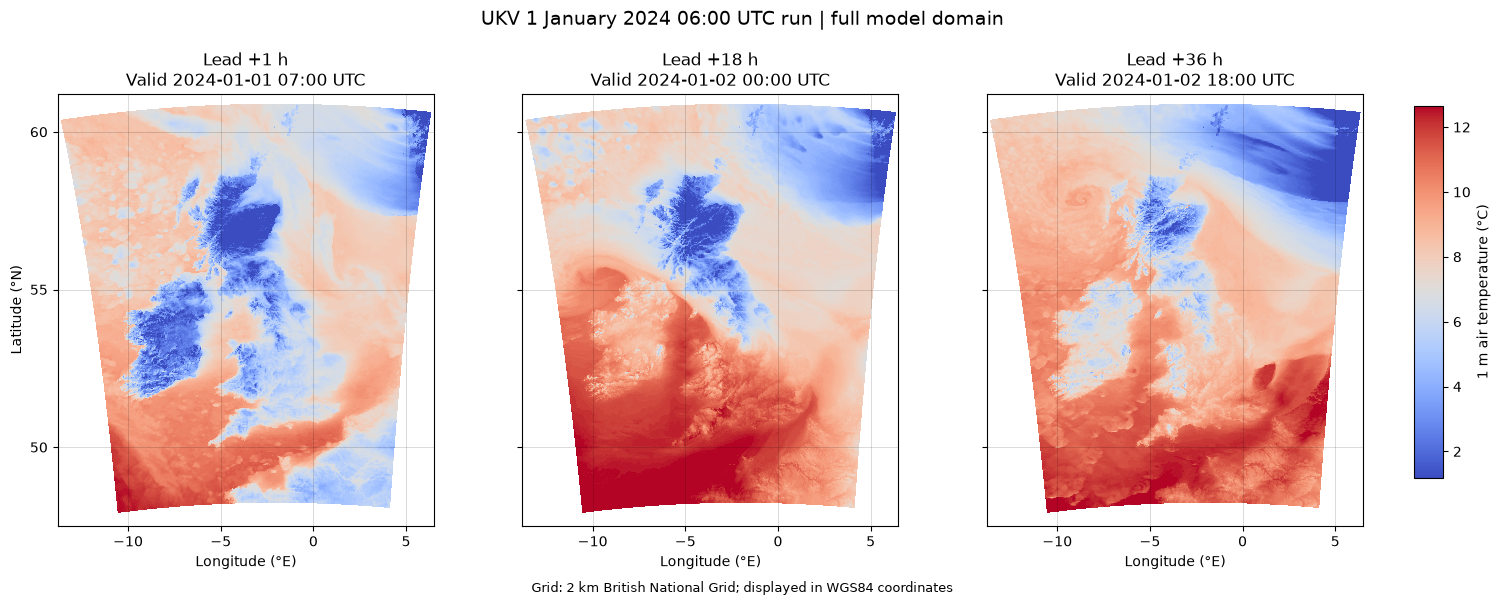

In [37]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from pyproj import Transformer

ukv_dir = Path("data/to_gitignore/ukv_20240101_06")
wholesale1 = ukv_dir / "202401010600_u1096_ng_umqv_Wholesale1.grib"
if not wholesale1.exists():
    raise FileNotFoundError(f"Download the UKV Wholesale1 file first: {wholesale1}")

# Use forecast leads, not lead 0 (the model initialization/analysis).
lead_hours = [1, 18, 36]
selected_steps = np.asarray(lead_hours, dtype="timedelta64[h]")
with xr.open_dataset(
    wholesale1,
    engine="cfgrib",
    backend_kwargs={
        "indexpath": "",
        "filter_by_keys": {
            "shortName": "t",
            "typeOfLevel": "heightAboveGround",
        },
    },
) as temperature_ds:
    temperature_k = (
        temperature_ds["t"]
        .sel(heightAboveGround=1)
        .sel(step=selected_steps)
        .values
    )
    valid_times = temperature_ds["valid_time"].sel(step=selected_steps).values

# The UKV grid is 548 x 704 at 2 km spacing in British National Grid.
# These are grid-cell centres, ordered west-to-east and north-to-south.
# GRIB grid centres from X1/X2/Y1/Y2: -238000..856000 E and
# 1222000..-184000 N, at 2 km spacing (548 x 704 points).
easting_m = np.linspace(-238_000, 856_000, 548)
northing_m = np.linspace(1_222_000, -184_000, 704)
if temperature_k.shape != (len(lead_hours), len(northing_m) * len(easting_m)):
    raise ValueError(
        f"Unexpected temperature array shape {temperature_k.shape}; "
        f"expected ({len(lead_hours)}, {len(northing_m) * len(easting_m)})"
    )

x_grid, y_grid = np.meshgrid(easting_m, northing_m)
to_wgs84 = Transformer.from_crs("EPSG:27700", "EPSG:4326", always_xy=True)
longitude, latitude = to_wgs84.transform(x_grid, y_grid)
temperature_c = temperature_k.reshape(
    len(lead_hours), len(northing_m), len(easting_m)
) - 273.15

vmin, vmax = np.nanpercentile(temperature_c, [2, 98])
fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharex=True, sharey=True)
for ax, lead, valid_time, field in zip(axes, lead_hours, valid_times, temperature_c):
    image = ax.pcolormesh(
        longitude,
        latitude,
        field,
        shading="auto",
        cmap="coolwarm",
        vmin=vmin,
        vmax=vmax,
        rasterized=True,
    )
    valid_time_text = np.datetime_as_string(valid_time, unit="m").replace("T", " ")
    ax.set_title(f"Lead +{lead} h\nValid {valid_time_text} UTC")
    ax.set_xlabel("Longitude (°E)")
    ax.set_xlim(-13.8, 6.5)
    ax.set_ylim(47.5, 61.2)
    ax.set_xticks([-10, -5, 0, 5])
    ax.set_yticks([50, 55, 60])
    ax.grid(color="black", alpha=0.2, linewidth=0.5)
    ax.set_aspect(1 / np.cos(np.deg2rad(54)))
axes[0].set_ylabel("Latitude (°N)")
fig.suptitle("UKV 1 January 2024 06:00 UTC run | full model domain", fontsize=14)
fig.text(0.5, 0.01, "Grid: 2 km British National Grid; displayed in WGS84 coordinates", ha="center", fontsize=9)
fig.subplots_adjust(top=0.84, bottom=0.12, left=0.06, right=0.90, wspace=0.12)
colorbar_ax = fig.add_axes([0.92, 0.20, 0.018, 0.62])
fig.colorbar(image, cax=colorbar_ax, label="1 m air temperature (°C)")

figure_path = ukv_dir / "ukv_temperature_forecast_steps.png"
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
print(f"Saved map: {figure_path}")
for lead, valid_time, field in zip(lead_hours, valid_times, temperature_c):
    valid_time_text = np.datetime_as_string(valid_time, unit="m").replace("T", " ")
    print(
        f"+{lead:2d} h, valid {valid_time_text} UTC: "
        f"{np.nanmin(field):.1f} to {np.nanmax(field):.1f} °C"
    )
plt.show()


### What the map shows

- The panels are one forecast run viewed at three leads: **+1 h** (1 January, 07:00 UTC), **+18 h** (2 January, 00:00 UTC), and **+36 h** (2 January, 18:00 UTC). Lead 0 is the model initialization, so the first panel is the earliest forecast step.
- Each panel uses the same temperature colour scale in °C: blue is colder and red is warmer.
- The plot shows the **full UKV domain** at its native 2 km grid spacing, transformed from British National Grid to WGS84 for longitude/latitude axes. It is not yet cropped around a GSP.

This confirms we can read actual forecast values and map them through the full +36 h range. The next spatial step is to locate the GSP centres on this grid and make the PVNet-sized local crop.


**PLANNING**

So far, we’ve shown that the satellite and UKV data can be inspected and plotted. We haven’t yet assembled a matched Jan 1–7 dataset or confirmed that PVNet can load a sample from it.

I suggest this order:
1. Check alignment with one sample. Use one representative GSP and one forecast start time, such as 1 January at 12:00 UTC. Confirm that PVLive targets, satellite inputs, and UKV fields can all be selected for the same example with the model’s expected shapes and timestamps.
2. Set the smoke-test scope and configuration. Start with one GSP to prove the pipeline, then expand to all intended GSPs for the week. The current model config has a short, explicit GSP ID mapping, so we’ll need to check that before a wider run. The generic training config also covers different dates and should not be used unchanged.
3. Fetch only the data the sampler needs. The satellite notebook’s successful batch is for 19 January, not the test week. Its one-day run took about 48 minutes, so I’d first adapt it to make a small Jan 1 sample. For UKV, we have inspected a 1 January 06 UTC run, but haven’t yet confirmed which cycles and forecast files PVNet needs across the week or verified every configured variable. We should resolve that before downloading a full week.
4. Check the time buffers. The current model settings use past satellite and NWP data and forecast generation targets for three hours. That means the data window must include context before Jan 1 and targets after Jan 7; we should derive the exact boundaries from the sampler before fetching.
5. Run a bounded PVNet smoke test. Once one example loads correctly, create a local config for Jan 1–7 and run a deliberately small, bounded training pass. That will tell us whether the full data path works before we spend time preparing the wider dataset.

I recommend the one-GSP check first, then expanding to all intended GSPs. The next useful check is to trace the sampler’s timestamp selection and GSP mapping, then write the pre-flight alignment cell in the notebook so you can see exactly what it selects.

## Choose the first PV_Live GSP by capacity

capacity_mwp is PV_Live's estimate of effective PV capacity in MWp, including estimated performance degradation. This cell queries the value at 2024-01-01 00:00 UTC for each GSP and ranks the regions, excluding the national aggregate (GSP 0).

Historical PV_Live data uses its current region definitions. The map below uses the matching NESO boundary release (2026-02-09). These are approximate modelling regions, not administrative borders.


In [10]:
from concurrent.futures import ThreadPoolExecutor
import time
import pandas as pd
import requests

PVLIVE_BASE = "https://api.pvlive.uk/pvlive/api/v4"
CAPACITY_TIME = "2024-01-01T00:00:00Z"
gsp_response = requests.get(f"{PVLIVE_BASE}/gsp_list", timeout=30)
gsp_response.raise_for_status()
gsp_rows = gsp_response.json()["data"]
gsp_names = {int(i): name for i, name, _ in gsp_rows if int(i) != 0}

def fetch_gsp_capacity(gsp_id):
    params = {"start": CAPACITY_TIME, "end": CAPACITY_TIME, "extra_field": "capacity_mwp"}
    for attempt in range(3):
        try:
            r = requests.get(f"{PVLIVE_BASE}/gsp/{gsp_id}", params=params, timeout=30)
            r.raise_for_status()
            data = r.json()
            if not data["data"]:
                return {"gsp_id": gsp_id, "gsp_name": gsp_names[gsp_id], "capacity_mwp": None}
            j = data["meta"].index("capacity_mwp")
            return {"gsp_id": gsp_id, "gsp_name": gsp_names[gsp_id],
                    "capacity_mwp": float(data["data"][0][j])}
        except (requests.RequestException, ValueError, KeyError) as error:
            if attempt == 2:
                raise RuntimeError(f"PV_Live request failed for GSP {gsp_id}") from error
            time.sleep(1 + attempt)

gsp_ids = sorted(gsp_names)
with ThreadPoolExecutor(max_workers=8) as pool:
    capacity_rows = list(pool.map(fetch_gsp_capacity, gsp_ids))
gsp_capacity = (pd.DataFrame(capacity_rows).dropna(subset=["capacity_mwp"])
                .sort_values("capacity_mwp", ascending=False).reset_index(drop=True))
display(gsp_capacity.head(10))
print(f"Retrieved capacity for {len(gsp_capacity)} of {len(gsp_ids)} PV_Live GSPs.")


,gsp_id,gsp_name,capacity_mwp
0,199,MELK_1,558.875
1,197,MANN_1,471.643
2,152,INDQ1,378.674
3,202,MITY_1,378.002
4,38,BRFO_1|CLT03,374.976
5,135,GREN_1,352.920
6,8,ALVE1,352.737
7,324,COWL_1,346.604
8,214,NORM_1|SALL1,339.541
9,47,BURM_1,333.101


Retrieved capacity for 334 of 334 PV_Live GSPs.


## Map the three highest-capacity GSPs

This uses the top three regions from the PV_Live capacity ranking and shows them on one Great Britain overview map.


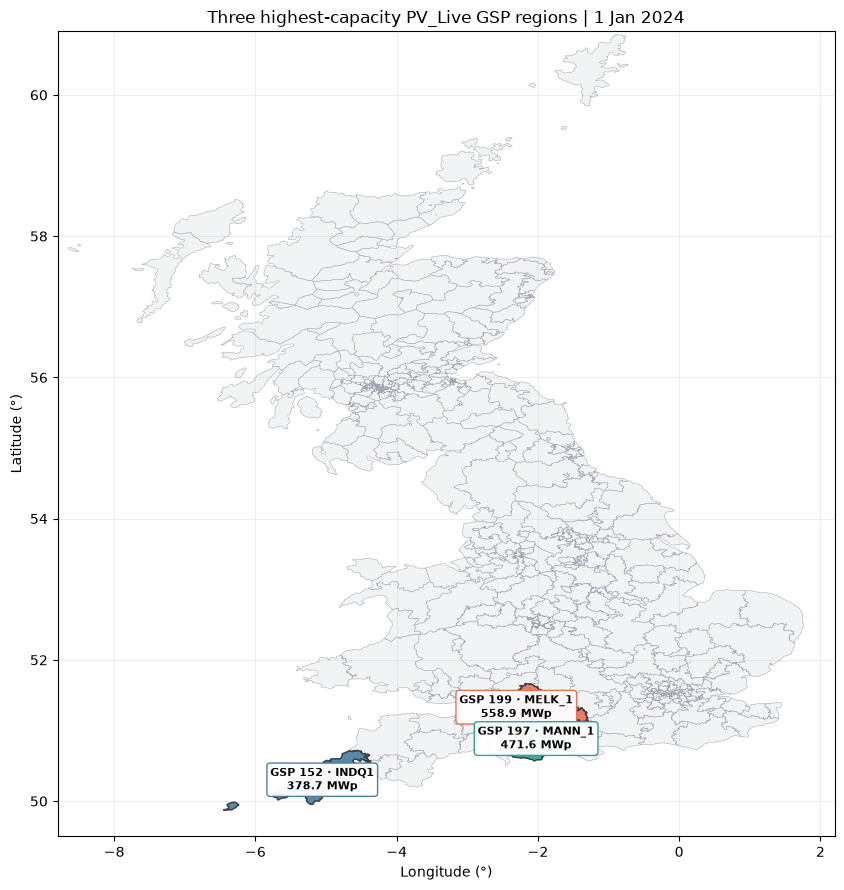

In [30]:
from io import BytesIO
import json
import zipfile

import matplotlib.pyplot as plt
import requests

NESO_GSP_ZIP = (
    "https://api.neso.energy/dataset/2810092e-d4b2-472f-b955-d8bea01f9ec0/"
    "resource/5dfab3dd-f192-40ab-b97f-b365a594293c/download/gsp_regions_20260209.zip"
)
with requests.get(NESO_GSP_ZIP, timeout=60) as response:
    response.raise_for_status()
    with zipfile.ZipFile(BytesIO(response.content)) as archive:
        boundary_data = json.loads(
            archive.read("Proj_4326/GSP_regions_4326_20260209.geojson")
        )

# The capacity table is already sorted from largest to smallest by the prior cell.
top_three_gsps = gsp_capacity.head(3).copy()
colors = ["#e76f51", "#2a9d8f", "#457b9d"]

def boundary_polygons(geometry):
    if geometry["type"] == "Polygon":
        return [geometry["coordinates"]]
    if geometry["type"] == "MultiPolygon":
        return geometry["coordinates"]
    raise ValueError(f"Unsupported boundary geometry: {geometry['type']}")

fig, ax = plt.subplots(figsize=(9, 9))
for feature in boundary_data["features"]:
    for rings in boundary_polygons(feature["geometry"]):
        exterior = rings[0]
        ax.fill([p[0] for p in exterior], [p[1] for p in exterior],
                facecolor="#f1f3f5", edgecolor="#9ca3af", linewidth=0.35, zorder=1)

for (_, gsp), color in zip(top_three_gsps.iterrows(), colors, strict=True):
    gsp_id = int(gsp["gsp_id"])
    gsp_name = gsp["gsp_name"]
    features = [f for f in boundary_data["features"]
                if gsp_name in str(f["properties"]["GSPs"]).split("|")]
    if not features:
        raise ValueError(f"No boundary found for GSP {gsp_id} ({gsp_name}).")

    all_points = []
    for feature in features:
        for rings in boundary_polygons(feature["geometry"]):
            exterior = rings[0]
            xs, ys = [p[0] for p in exterior], [p[1] for p in exterior]
            ax.fill(xs, ys, facecolor=color, edgecolor="#30343b", linewidth=1.1,
                    alpha=0.88, zorder=2)
            all_points.extend(exterior)

    label_lon = sum(p[0] for p in all_points) / len(all_points)
    label_lat = sum(p[1] for p in all_points) / len(all_points)
    ax.annotate(
        f"GSP {gsp_id} · {gsp_name}\n{gsp['capacity_mwp']:.1f} MWp",
        (label_lon, label_lat), ha="center", va="center", fontsize=8, weight="bold",
        bbox={"boxstyle":"round,pad=0.3", "facecolor":"white", "edgecolor":color, "alpha":0.96},
        zorder=3,
    )

ax.set_xlim(-8.8, 2.2)
ax.set_ylim(49.5, 60.9)
ax.set_title("Three highest-capacity PV_Live GSP regions | 1 Jan 2024")
ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
plt.tight_layout()


^ great, though it would have been nice to show the top three on the map. Only really need one map; don't really need the zoom-in.

## One-sample alignment check: GSP 199 at 12:00 UTC

This derives the time windows from the current model and data YAML files, checks which local satellite and UKV files exist, and queries PV_Live for the target GSP. It does not download or process satellite files.

With the current model settings, the sampler expects satellite frames from 11:30–12:00 UTC, UKV valid times from 11:00–15:00 UTC, and generation values from 11:00–15:00 UTC at 30-minute intervals. The UKV NWP dropout settings select a run initialized no later than 06:00 UTC for this example.


In [31]:
from pathlib import Path
from datetime import timedelta

import pandas as pd
import requests
import yaml

t0 = pd.Timestamp("2024-01-01T12:00:00Z")
gsp_id = 199
model_path = Path("../configs/model/late_fusion.yaml")
data_path = Path("../configs/datamodule/configuration/example_configuration.yaml")
model_cfg = yaml.safe_load(model_path.read_text())["model"]
data_cfg = yaml.safe_load(data_path.read_text())["input_data"]

# Match the sequence lengths and interval-end adjustment used in PVNet's config preparation.
sat_cfg = data_cfg["satellite"]
sat_step = sat_cfg["time_resolution_minutes"]
sat_length = (model_cfg["sat_history_minutes"] - model_cfg["min_sat_delay_minutes"]) // sat_step + 1
sat_start = sat_cfg["interval_start_minutes"]
sat_end = sat_start + (sat_length - 1) * sat_step
sat_times = pd.date_range(t0 + pd.Timedelta(minutes=sat_start),
                          t0 + pd.Timedelta(minutes=sat_end), freq=f"{sat_step}min")

nwp_cfg = data_cfg["nwp"]["ukv"]
nwp_step = nwp_cfg["time_resolution_minutes"]
nwp_history = model_cfg["nwp_history_minutes"]["ukv"]
nwp_forecast = model_cfg["nwp_forecast_minutes"]["ukv"]
nwp_length = nwp_history // nwp_step + nwp_forecast // nwp_step + 1
nwp_start = nwp_cfg["interval_start_minutes"]
nwp_end = nwp_start + (nwp_length - 1) * nwp_step
nwp_times = pd.date_range(t0 + pd.Timedelta(minutes=nwp_start),
                          t0 + pd.Timedelta(minutes=nwp_end), freq=f"{nwp_step}min")

gen_cfg = data_cfg["generation"]
gen_start = gen_cfg["interval_start_minutes"]
gen_end = model_cfg["forecast_minutes"]
gen_step = gen_cfg["time_resolution_minutes"]
generation_times = pd.date_range(t0 + pd.Timedelta(minutes=gen_start),
                                 t0 + pd.Timedelta(minutes=gen_end), freq=f"{gen_step}min")

print("Satellite times expected by the sampler:")
print(sat_times.strftime("%Y-%m-%d %H:%M UTC").to_list())
print("\nUKV valid times expected by the sampler:")
print(nwp_times.strftime("%Y-%m-%d %H:%M UTC").to_list())
dropout_minutes = min(nwp_cfg["dropout_timedeltas_minutes"])
required_init_cutoff = t0 + pd.Timedelta(minutes=dropout_minutes)
print(f"UKV run must be initialized no later than {required_init_cutoff:%Y-%m-%d %H:%M UTC}.")
print("Required forecast leads from the 06:00 run:",
      [(time - pd.Timestamp("2024-01-01T06:00:00Z")).total_seconds() / 3600
       for time in nwp_times], "hours")
print("\nPVLive generation target times:")
print(generation_times.strftime("%Y-%m-%d %H:%M UTC").to_list())

# Check local data availability relative to the required satellite sequence.
satellite_root = Path("data/satellite/rss_2024_test")
jan1_crops = sorted(satellite_root.rglob("*20240101*satpy.nc"))
jan1_native = sorted(
    list(satellite_root.rglob("*20240101*.nat"))
    + list(Path("data/to_gitignore").rglob("*20240101*.nat"))
)
print(f"\nJan 1 processed satellite crops found: {len(jan1_crops)}")
print(f"Jan 1 native satellite products found under data/satellite: {len(jan1_native)}")
for path in jan1_native:
    print(" ", path)

ukv_dir = Path("data/to_gitignore/ukv_20240101_06")
ukv_files = sorted(ukv_dir.glob("202401010600*Wholesale*.grib"))
print(f"\nJan 1 06:00 UKV GRIB files found: {len(ukv_files)}")
for path in ukv_files:
    print(" ", path.name)

# Retrieve the PVLive target and capacity series for GSP 199 over the required target window.
pvlive_url = f"https://api.pvlive.uk/pvlive/api/v4/gsp/{gsp_id}"
response = requests.get(
    pvlive_url,
    params={
        "start": generation_times[0].strftime("%Y-%m-%dT%H:%M:%SZ"),
        "end": generation_times[-1].strftime("%Y-%m-%dT%H:%M:%SZ"),
        "extra_field": "capacity_mwp",
    },
    timeout=30,
)
response.raise_for_status()
payload = response.json()
pvlive_targets = pd.DataFrame(payload["data"], columns=payload["meta"])
pvlive_targets["datetime_gmt"] = pd.to_datetime(pvlive_targets["datetime_gmt"], utc=True)
display(pvlive_targets.sort_values("datetime_gmt"))
print(f"\nReceived {len(pvlive_targets)} PVLive rows for GSP {gsp_id}.")


Satellite times expected by the sampler:
['2024-01-01 11:30 UTC', '2024-01-01 11:35 UTC', '2024-01-01 11:40 UTC', '2024-01-01 11:45 UTC', '2024-01-01 11:50 UTC', '2024-01-01 11:55 UTC', '2024-01-01 12:00 UTC']

UKV valid times expected by the sampler:
['2024-01-01 11:00 UTC', '2024-01-01 12:00 UTC', '2024-01-01 13:00 UTC', '2024-01-01 14:00 UTC', '2024-01-01 15:00 UTC']
UKV run must be initialized no later than 2024-01-01 06:00 UTC.
Required forecast leads from the 06:00 run: [5.0, 6.0, 7.0, 8.0, 9.0] hours

PVLive generation target times:
['2024-01-01 11:00 UTC', '2024-01-01 11:30 UTC', '2024-01-01 12:00 UTC', '2024-01-01 12:30 UTC', '2024-01-01 13:00 UTC', '2024-01-01 13:30 UTC', '2024-01-01 14:00 UTC', '2024-01-01 14:30 UTC', '2024-01-01 15:00 UTC']

Jan 1 processed satellite crops found: 7
Jan 1 native satellite products found under data/satellite: 1
  data/to_gitignore/MSG4-SEVI-MSG15-0100-NA-20240101120417/MSG4-SEVI-MSG15-0100-NA-20240101120417.851000000Z-NA.nat

Jan 1 06:00 UKV 

,gsp_id,datetime_gmt,generation_mw,capacity_mwp
8,199,2024-01-01 11:00:00+00:00,64.332,558.875
7,199,2024-01-01 11:30:00+00:00,53.447,558.875
6,199,2024-01-01 12:00:00+00:00,42.457,558.875
5,199,2024-01-01 12:30:00+00:00,39.019,558.875
4,199,2024-01-01 13:00:00+00:00,38.236,558.875
3,199,2024-01-01 13:30:00+00:00,28.271,558.875
2,199,2024-01-01 14:00:00+00:00,17.294,558.875
1,199,2024-01-01 14:30:00+00:00,8.999,558.875
0,199,2024-01-01 15:00:00+00:00,4.371,558.875



Received 9 PVLive rows for GSP 199.


## Crop the UKV and satellite grids around GSP 199

This checks the configured UKV fields against the downloaded Wholesale files, selects the sampler-sized 24×24 UKV and satellite crops around GSP 199, and plots both footprints over the GSP boundary. The crop centre uses the OCF sampler’s bundled 2025 GSP coordinate table as a provisional location; when we build the local PVLive generation dataset, its own longitude/latitude will be the authoritative sample centre.

The GRIB grid coordinates are read from its projection metadata, rather than inferred from the map image. The channel aliases shown below are the only translation currently applied: sdswrf→dswrf, sdlwrf→dlwrf, and cbh→cdcb.


,model_channel,GRIB variable,units
0,t,t,K
1,dswrf,sdswrf,W m**-2
2,dlwrf,sdlwrf,W m**-2
3,hcc,hcc,%
4,mcc,mcc,%
5,lcc,lcc,%
6,sde,sde,m
7,r,r,%
8,vis,vis,m
9,si10,si10,m s**-1


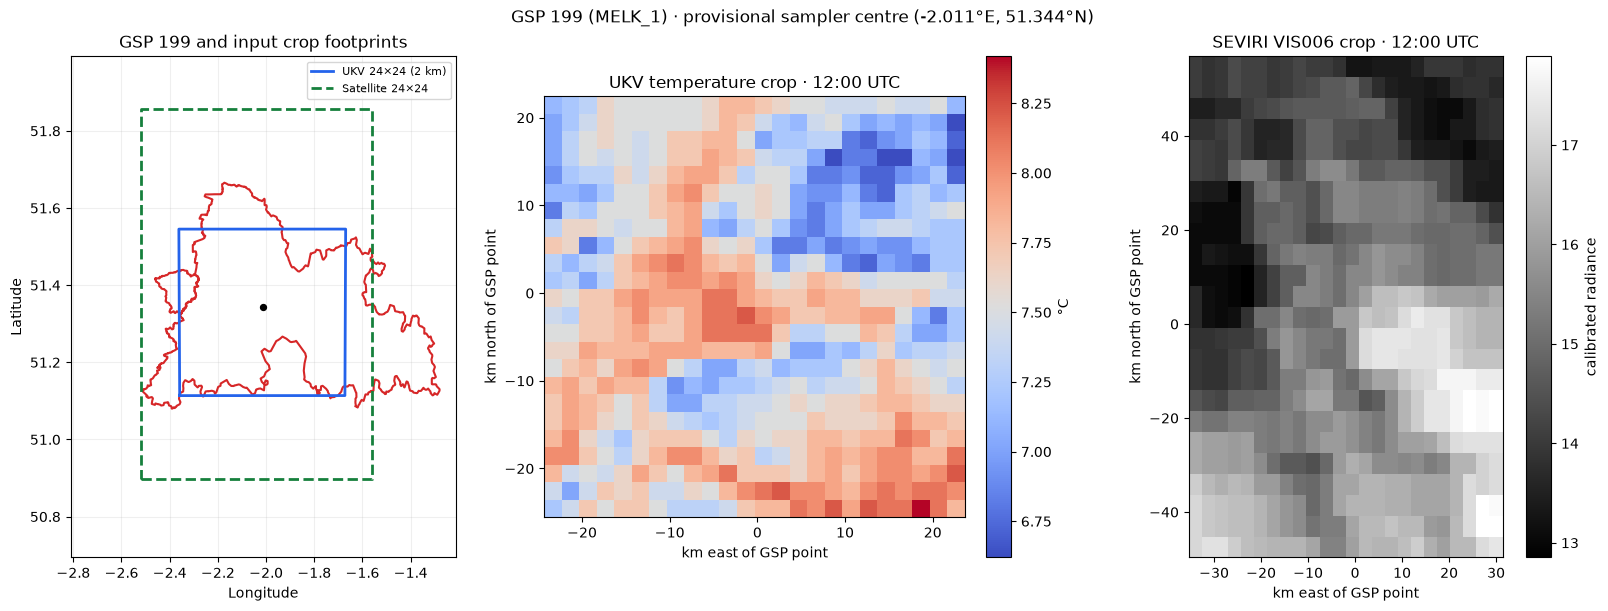

UKV crop shape: (5, 17, 24, 24) = time, channel, y, x; NWP valid times: [Timestamp('2024-01-01 11:00:00+0000', tz='UTC'), Timestamp('2024-01-01 12:00:00+0000', tz='UTC'), Timestamp('2024-01-01 13:00:00+0000', tz='UTC'), Timestamp('2024-01-01 14:00:00+0000', tz='UTC'), Timestamp('2024-01-01 15:00:00+0000', tz='UTC')]
Satellite crop shape: (24, 24); 24×24 frame selected at nominal 12:00 UTC.
Grid centres from GRIB metadata: x -238000…856000 m, y -184000…1222000 m.


In [32]:
from pathlib import Path

import cfgrib
import matplotlib.pyplot as plt
import numpy as np
import ocf_data_sampler
import pandas as pd
import xarray as xr
import yaml
from eccodes import codes_get, codes_grib_new_from_file, codes_release
from pyproj import Transformer

GSP_ID = 199
GSP_NAME = "MELK_1"
T0 = pd.Timestamp("2024-01-01T12:00:00Z")
UKV_DIR = Path("data/to_gitignore/ukv_20240101_06")
UKV_FILES = sorted(UKV_DIR.glob("202401010600_u1096_ng_umqv_Wholesale*.grib"))
if len(UKV_FILES) != 2:
    raise FileNotFoundError(f"Expected Wholesale1 and Wholesale2 GRIB files, found {UKV_FILES}")

# Use the location table distributed with the installed OCF sampler for this exploratory crop.
location_csv = (Path(ocf_data_sampler.__file__).parent
                / "gsp_location_data_legacy_format" / "uk_gsp_locations_20250109.csv")
locations = pd.read_csv(location_csv, usecols=["gsp_id", "gsp_name", "x_osgb", "y_osgb"])
location_row = locations.loc[locations.gsp_id.eq(GSP_ID)]
if len(location_row) != 1 or location_row.iloc[0].gsp_name != GSP_NAME:
    raise ValueError(f"Could not resolve expected sampler location for GSP {GSP_ID} ({GSP_NAME}).")
gsp_x = float(location_row.iloc[0].x_osgb)
gsp_y = float(location_row.iloc[0].y_osgb)

# Read first/last grid-cell centres directly from a representative GRIB message.
grid_info = None
with UKV_FILES[0].open("rb") as stream:
    while True:
        gid = codes_grib_new_from_file(stream)
        if gid is None:
            break
        try:
            if codes_get(gid, "shortName") == "t" and codes_get(gid, "level") == 1:
                grid_info = {
                    "nx": int(codes_get(gid, "Ni")),
                    "ny": int(codes_get(gid, "Nj")),
                    "x_first": float(codes_get(gid, "X1InGridLengths")),
                    "x_last": float(codes_get(gid, "X2InGridLengths")),
                    "y_first": float(codes_get(gid, "Y1InGridLengths")),
                    "y_last": float(codes_get(gid, "Y2InGridLengths")),
                }
                break
        finally:
            codes_release(gid)
if grid_info is None:
    raise ValueError("Could not read the UKV Transverse Mercator grid metadata.")
ukv_x = np.linspace(grid_info["x_first"], grid_info["x_last"], grid_info["nx"])
# The raw GRIB is north-to-south; PVNet's UKV loader stores y coordinates increasing.
ukv_y = np.linspace(grid_info["y_first"], grid_info["y_last"], grid_info["ny"])[::-1]
if not np.allclose(np.diff(ukv_x), 2000) or not np.allclose(np.diff(ukv_y), 2000):
    raise ValueError(f"Unexpected UKV grid spacing: dx={np.unique(np.diff(ukv_x))}, dy={np.unique(np.diff(ukv_y))}")

# Match the PVNet data channel order; these names map the local GRIB encoding to config names.
source_for_model_channel = {
    "t": "t", "dswrf": "sdswrf", "dlwrf": "sdlwrf", "hcc": "hcc",
    "mcc": "mcc", "lcc": "lcc", "sde": "sde", "r": "r", "vis": "vis",
    "si10": "si10", "wdir10": "wdir10", "prate": "prate", "hcct": "hcct",
    "cdcb": "cbh", "dpt": "dpt", "prmsl": "prmsl", "h": "h",
}
model_cfg = yaml.safe_load(Path("../configs/model/late_fusion.yaml").read_text())["model"]
data_cfg = yaml.safe_load(Path("../configs/datamodule/configuration/example_configuration.yaml").read_text())["input_data"]
model_channels = data_cfg["nwp"]["ukv"]["channels"]
if model_channels != list(source_for_model_channel):
    raise ValueError(f"Unexpected UKV channel order in YAML: {model_channels}")
if model_cfg["nwp_encoders_dict"]["ukv"]["in_channels"] != len(model_channels):
    raise ValueError("Model UKV encoder channel count does not match the data configuration.")

nwp_valid_times = pd.date_range(T0 - pd.Timedelta(hours=1), T0 + pd.Timedelta(hours=3), freq="1h")
run_time = pd.Timestamp("2024-01-01T06:00:00Z")
steps = np.asarray([(time - run_time).to_timedelta64() for time in nwp_valid_times])
center_i = int(np.abs(ukv_x - gsp_x).argmin())
center_j = int(np.abs(ukv_y - gsp_y).argmin())
x_slice = slice(center_i - 12, center_i + 12)
y_slice = slice(center_j - 12, center_j + 12)
if x_slice.start < 0 or y_slice.start < 0 or x_slice.stop > len(ukv_x) or y_slice.stop > len(ukv_y):
    raise ValueError("The 24×24 UKV crop would extend outside the model grid.")

nwp_crop = np.empty((len(steps), len(model_channels), 24, 24), dtype=np.float32)
channel_rows = {}
found_channels = set()
for grib_path in UKV_FILES:
    with xr.set_options(use_new_combine_kwarg_defaults=True):
        groups = cfgrib.open_datasets(str(grib_path), backend_kwargs={"indexpath": ""})
    try:
        for ds in groups:
            for model_channel, source_var in source_for_model_channel.items():
                if model_channel in found_channels or source_var not in ds.data_vars:
                    continue
                field = ds[source_var]
                if model_channel == "t":
                    field = field.sel(heightAboveGround=1)
                field = field.sel(step=steps)
                values = np.asarray(field.values)
                if values.shape != (len(steps), grid_info["nx"] * grid_info["ny"]):
                    raise ValueError(f"Unexpected {source_var} shape {values.shape}")
                values = values.reshape(len(steps), grid_info["ny"], grid_info["nx"])[:, ::-1, :]
                nwp_crop[:, model_channels.index(model_channel)] = values[:, y_slice, x_slice]
                channel_rows[model_channel] = {
                    "model_channel": model_channel,
                    "GRIB variable": source_var,
                    "units": field.attrs.get("units", ""),
                }
                found_channels.add(model_channel)
    finally:
        for ds in groups:
            ds.close()
missing = [channel for channel in model_channels if channel not in found_channels]
if missing:
    raise ValueError(f"Configured UKV channels not found in the two GRIBs: {missing}")
channel_mapping_table = pd.DataFrame([channel_rows[c] for c in model_channels])
display(channel_mapping_table)

# The third hourly target is 12:00 UTC, the selected forecast start time.
t0_nwp_index = list(nwp_valid_times).index(T0)
temperature_c = nwp_crop[t0_nwp_index, model_channels.index("t")] - 273.15
crop_x = ukv_x[x_slice]
crop_y = ukv_y[y_slice]

# Use the identical pixel-centred 24×24 selection on the processed SEVIRI crop.
SAT_FILE = Path("data/satellite/rss_2024_test/jan1_noon_alignment/SEVIRI_RSS_20240101T120000Z_GB_local_satpy.nc")
if not SAT_FILE.exists():
    raise FileNotFoundError(f"Run the seven-scan satellite processing cell first: {SAT_FILE}")
lon_lat = Transformer.from_crs("EPSG:27700", "EPSG:4326", always_xy=True)
gsp_lon, gsp_lat = lon_lat.transform(gsp_x, gsp_y)
with xr.open_dataset(SAT_FILE, engine="h5netcdf") as sat_ds:
    sat_i = int(np.abs(sat_ds.lon.values - gsp_lon).argmin())
    sat_j = int(np.abs(sat_ds.lat.values - gsp_lat).argmin())
    sx_slice, sy_slice = slice(sat_i - 12, sat_i + 12), slice(sat_j - 12, sat_j + 12)
    if sx_slice.start < 0 or sy_slice.start < 0 or sx_slice.stop > sat_ds.sizes["x"] or sy_slice.stop > sat_ds.sizes["y"]:
        raise ValueError("The 24×24 satellite crop would extend outside the processed grid.")
    sat_crop = sat_ds["channel_1"].isel(x=sx_slice, y=sy_slice).load()
    sat_lon, sat_lat = sat_ds.lon.isel(x=sx_slice).values, sat_ds.lat.isel(y=sy_slice).values

# Current NESO boundary version: outline the selected GSP and both crop footprints.
gsp_features = [f for f in boundary_data["features"]
                if GSP_NAME in str(f["properties"]["GSPs"]).split("|")]
if not gsp_features:
    raise ValueError(f"No current NESO boundary found for {GSP_NAME}.")
x_left, x_right = crop_x[0] - 1000, crop_x[-1] + 1000
y_bottom, y_top = crop_y[0] - 1000, crop_y[-1] + 1000
nwp_corner_x = np.array([x_left, x_right, x_right, x_left, x_left])
nwp_corner_y = np.array([y_bottom, y_bottom, y_top, y_top, y_bottom])
nwp_corner_lon, nwp_corner_lat = lon_lat.transform(nwp_corner_x, nwp_corner_y)
sat_dx, sat_dy = np.median(np.abs(np.diff(sat_lon))), np.median(np.abs(np.diff(sat_lat)))
sat_left, sat_right = sat_lon.min() - sat_dx/2, sat_lon.max() + sat_dx/2
sat_bottom, sat_top = sat_lat.min() - sat_dy/2, sat_lat.max() + sat_dy/2

fig, axes = plt.subplots(1, 3, figsize=(16, 6), constrained_layout=True)
map_ax, ukv_ax, sat_ax = axes
for feature in gsp_features:
    geometry = feature["geometry"]
    polygon_list = [geometry["coordinates"]] if geometry["type"] == "Polygon" else geometry["coordinates"]
    for rings in polygon_list:
        exterior = rings[0]
        map_ax.plot([p[0] for p in exterior], [p[1] for p in exterior], color="#d62728", linewidth=1.5)
map_ax.plot(nwp_corner_lon, nwp_corner_lat, color="#2463eb", linewidth=2, label="UKV 24×24 (2 km)")
map_ax.plot([sat_left,sat_right,sat_right,sat_left,sat_left],
            [sat_bottom,sat_bottom,sat_top,sat_top,sat_bottom],
            color="#16803c", linestyle="--", linewidth=2, label="Satellite 24×24")
map_ax.scatter([gsp_lon],[gsp_lat],color="black",s=18,zorder=4)
map_ax.set_xlim(gsp_lon - 0.8, gsp_lon + 0.8)
map_ax.set_ylim(gsp_lat - 0.65, gsp_lat + 0.65)
map_ax.set_aspect(1 / np.cos(np.deg2rad(gsp_lat)))
map_ax.set(title="GSP 199 and input crop footprints", xlabel="Longitude", ylabel="Latitude")
map_ax.legend(fontsize=8)
map_ax.grid(alpha=0.2)

ukv_mesh = ukv_ax.pcolormesh((crop_x-gsp_x)/1000, (crop_y-gsp_y)/1000,
                             temperature_c, shading="auto", cmap="coolwarm")
ukv_ax.set(title="UKV temperature crop · 12:00 UTC", xlabel="km east of GSP point", ylabel="km north of GSP point")
ukv_ax.set_aspect("equal", adjustable="box")
fig.colorbar(ukv_mesh, ax=ukv_ax, label="°C")

sat_x_km = (sat_lon - gsp_lon) * 111.32 * np.cos(np.deg2rad(gsp_lat))
sat_y_km = (sat_lat - gsp_lat) * 111.32
sat_mesh = sat_ax.pcolormesh(sat_x_km, sat_y_km, sat_crop.values, shading="auto", cmap="gray")
sat_ax.set(title="SEVIRI VIS006 crop · 12:00 UTC", xlabel="km east of GSP point", ylabel="km north of GSP point")
sat_ax.set_aspect("equal", adjustable="box")
fig.colorbar(sat_mesh, ax=sat_ax, label="calibrated radiance")
fig.suptitle(f"GSP {GSP_ID} ({GSP_NAME}) · provisional sampler centre ({gsp_lon:.3f}°E, {gsp_lat:.3f}°N)")
plt.show()
print(f"UKV crop shape: {nwp_crop.shape} = time, channel, y, x; NWP valid times: {nwp_valid_times.tolist()}")
print(f"Satellite crop shape: {sat_crop.shape}; 24×24 frame selected at nominal 12:00 UTC.")
print(f"Grid centres from GRIB metadata: x {ukv_x[0]:.0f}…{ukv_x[-1]:.0f} m, y {ukv_y[0]:.0f}…{ukv_y[-1]:.0f} m.")


## Assemble and audit one raw multimodal sample

This combines the seven 5-minute satellite frames, five hourly UKV frames, and PV_Live generation/capacity series around 12:00 UTC for GSP 199. Arrays are kept in physical/source units here; this is an alignment and data-quality check, not yet a model-ready sample. In particular, the satellite source is calibrated to reflectance (%) or brightness temperature (K), while PVNet's configured satellite normalization constants are much smaller. The candidate scaling is printed for investigation but deliberately not applied until we confirm the training-data preprocessing.

Run the prior crop cell first. Its GSP centre is still provisional; use the PV_Live generation dataset's own GSP coordinates before making a final sample.

In [33]:
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import xarray as xr
import yaml

# This cell uses the 24x24 centre/crops and channel order from the preceding cell.
if not all(name in globals() for name in ("gsp_x", "gsp_y", "gsp_lon", "gsp_lat", "sat_i", "sat_j", "nwp_crop", "model_channels", "ukv_x", "ukv_y", "x_slice", "y_slice", "sat_ds")):
    raise RuntimeError("Run the preceding 'Crop the UKV and satellite grids' cell first.")

sample_t0 = pd.Timestamp("2024-01-01T12:00:00Z")
model_cfg = yaml.safe_load(Path("../configs/model/late_fusion.yaml").read_text())["model"]
data_cfg = yaml.safe_load(Path("../configs/datamodule/configuration/example_configuration.yaml").read_text())["input_data"]
satellite_channels = data_cfg["satellite"]["channels"]  # PVNet config order
sat_var_for_channel = {
    "VIS006": "channel_1", "VIS008": "channel_2", "IR_016": "channel_3",
    "IR_039": "channel_4", "WV_062": "channel_5", "WV_073": "channel_6",
    "IR_087": "channel_7", "IR_097": "channel_8", "IR_108": "channel_9",
    "IR_120": "channel_10", "IR_134": "channel_11",
}
sat_times = pd.date_range(sample_t0 - pd.Timedelta(minutes=30), sample_t0, freq="5min")
satellite_raw = np.empty((len(sat_times), len(satellite_channels), 24, 24), dtype=np.float32)
satellite_raw.fill(np.nan)
satellite_units = {}
satellite_calibration = {}
satellite_root = Path("data/satellite/rss_2024_test/jan1_noon_alignment")
for time_index, scan_time in enumerate(sat_times):
    sat_path = satellite_root / f"SEVIRI_RSS_{scan_time:%Y%m%dT%H%M%SZ}_GB_local_satpy.nc"
    if not sat_path.exists():
        raise FileNotFoundError(f"Missing satellite scan: {sat_path}")
    with xr.open_dataset(sat_path, engine="h5netcdf") as frame:
        for channel_index, channel_name in enumerate(satellite_channels):
            variable = sat_var_for_channel[channel_name]
            values = frame[variable].isel(x=slice(sat_i - 12, sat_i + 12), y=slice(sat_j - 12, sat_j + 12)).values
            if values.shape != (24, 24):
                raise ValueError(f"Unexpected {channel_name} frame shape: {values.shape}")
            satellite_raw[time_index, channel_index] = values
            satellite_units[channel_name] = frame[variable].attrs.get("units", "")
            satellite_calibration[channel_name] = frame[variable].attrs.get("calibration", "")

nwp_cfg = data_cfg["nwp"]["ukv"]
nwp_step_minutes = nwp_cfg["time_resolution_minutes"]
nwp_length = (model_cfg["nwp_history_minutes"]["ukv"] + model_cfg["nwp_forecast_minutes"]["ukv"]) // nwp_step_minutes + 1
nwp_valid_times = pd.date_range(
    sample_t0 + pd.Timedelta(minutes=nwp_cfg["interval_start_minutes"]),
    periods=nwp_length, freq=f"{nwp_step_minutes}min",
)
if nwp_crop.shape != (len(nwp_valid_times), len(model_channels), 24, 24):
    raise ValueError(f"UKV sample shape/times mismatch: {nwp_crop.shape}")

generation_cfg = data_cfg["generation"]
generation_times = pd.date_range(
    sample_t0 + pd.Timedelta(minutes=generation_cfg["interval_start_minutes"]),
    sample_t0 + pd.Timedelta(minutes=model_cfg["forecast_minutes"]),
    freq=f"{generation_cfg['time_resolution_minutes']}min",
)
response = requests.get(
    f"https://api.pvlive.uk/pvlive/api/v4/gsp/{GSP_ID}",
    params={"start": generation_times[0].strftime("%Y-%m-%dT%H:%M:%SZ"),
            "end": generation_times[-1].strftime("%Y-%m-%dT%H:%M:%SZ"),
            "extra_field": "capacity_mwp"},
    timeout=30,
)
response.raise_for_status()
payload = response.json()
generation = pd.DataFrame(payload["data"], columns=payload["meta"])
generation["datetime_gmt"] = pd.to_datetime(generation["datetime_gmt"], utc=True)
expected_times = pd.DatetimeIndex(generation_times)
generation = generation.sort_values("datetime_gmt").reset_index(drop=True)
returned_times = pd.DatetimeIndex(generation["datetime_gmt"])
if not returned_times.equals(expected_times):
    raise ValueError(f"PV_Live time grid differs from configured target grid. Expected {list(expected_times)}, got {list(returned_times)}")
if generation[["generation_mw", "capacity_mwp"]].isna().any().any():
    raise ValueError("PV_Live returned missing generation or capacity values.")
generation["generation_fraction_of_capacity"] = generation["generation_mw"] / generation["capacity_mwp"]

print("One sample time: 2024-01-01 12:00 UTC | GSP", GSP_ID, GSP_NAME)
print("Raw satellite array (time, configured channel, y, x):", satellite_raw.shape, "times:", list(sat_times))
print("Raw UKV array (time, configured channel, y, x):", nwp_crop.shape, "times:", list(nwp_valid_times))
print("PV_Live target rows expected/received:", len(generation_times), len(generation))
display(generation[["datetime_gmt", "generation_mw", "capacity_mwp", "generation_fraction_of_capacity"]])

# Audit satellite source units and ranges beside configured normalization statistics.
sat_stats = data_cfg["satellite"]["normalisation_constants"]
satellite_audit_rows = []
for index, channel_name in enumerate(satellite_channels):
    values = satellite_raw[:, index]
    valid = values[np.isfinite(values)]
    configured_mean = sat_stats[channel_name]["mean"]
    candidate_divisor = 100.0 if satellite_calibration[channel_name] == "reflectance" else 300.0
    satellite_audit_rows.append({
        "channel": channel_name, "units": satellite_units[channel_name],
        "calibration": satellite_calibration[channel_name],
        "raw median": float(np.nanmedian(valid)) if valid.size else np.nan,
        "median / candidate divisor": float(np.nanmedian(valid) / candidate_divisor) if valid.size else np.nan,
        "PVNet configured mean": configured_mean,
        "valid fraction": float(np.isfinite(values).mean()),
    })
display(pd.DataFrame(satellite_audit_rows))

print("UKV finite fraction by channel:")
display(pd.DataFrame({"channel": model_channels, "finite_fraction": np.isfinite(nwp_crop).mean(axis=(0, 2, 3)), "min": np.nanmin(nwp_crop, axis=(0, 2, 3)), "max": np.nanmax(nwp_crop, axis=(0, 2, 3))}))

# Keep explicitly named raw arrays for the next step; no satellite scaling is applied here.
ukv_raw = nwp_crop.copy()
print("Audit complete. satellite_raw and ukv_raw are source-scale arrays; generation contains PV_Live targets.")

One sample time: 2024-01-01 12:00 UTC | GSP 199 MELK_1
Raw satellite array (time, configured channel, y, x): (7, 11, 24, 24) times: [Timestamp('2024-01-01 11:30:00+0000', tz='UTC'), Timestamp('2024-01-01 11:35:00+0000', tz='UTC'), Timestamp('2024-01-01 11:40:00+0000', tz='UTC'), Timestamp('2024-01-01 11:45:00+0000', tz='UTC'), Timestamp('2024-01-01 11:50:00+0000', tz='UTC'), Timestamp('2024-01-01 11:55:00+0000', tz='UTC'), Timestamp('2024-01-01 12:00:00+0000', tz='UTC')]
Raw UKV array (time, configured channel, y, x): (5, 17, 24, 24) times: [Timestamp('2024-01-01 11:00:00+0000', tz='UTC'), Timestamp('2024-01-01 12:00:00+0000', tz='UTC'), Timestamp('2024-01-01 13:00:00+0000', tz='UTC'), Timestamp('2024-01-01 14:00:00+0000', tz='UTC'), Timestamp('2024-01-01 15:00:00+0000', tz='UTC')]
PV_Live target rows expected/received: 9 9


,datetime_gmt,generation_mw,capacity_mwp,generation_fraction_of_capacity
0,2024-01-01 11:00:00+00:00,64.332,558.875,0.115110
1,2024-01-01 11:30:00+00:00,53.447,558.875,0.095633
2,2024-01-01 12:00:00+00:00,42.457,558.875,0.075969
3,2024-01-01 12:30:00+00:00,39.019,558.875,0.069817
4,2024-01-01 13:00:00+00:00,38.236,558.875,0.068416
5,2024-01-01 13:30:00+00:00,28.271,558.875,0.050586
6,2024-01-01 14:00:00+00:00,17.294,558.875,0.030944
7,2024-01-01 14:30:00+00:00,8.999,558.875,0.016102
8,2024-01-01 15:00:00+00:00,4.371,558.875,0.007821


,channel,units,calibration,raw median,median / candidate divisor,PVNet configured mean,valid fraction
0,IR_016,%,reflectance,14.168198,0.141682,0.175942,1.0
1,IR_039,K,brightness_temperature,262.208282,0.874028,0.861676,1.0
2,IR_087,K,brightness_temperature,232.931610,0.776439,0.771932,1.0
3,IR_097,K,brightness_temperature,220.600540,0.735335,0.801421,1.0
4,IR_108,K,brightness_temperature,232.830017,0.776100,0.712548,1.0
5,IR_120,K,brightness_temperature,231.135757,0.770452,0.890586,1.0
6,IR_134,K,brightness_temperature,224.940109,0.749800,0.944365,1.0
7,VIS006,%,reflectance,15.027122,0.150271,0.096333,1.0
8,VIS008,%,reflectance,17.966978,0.179670,0.114261,1.0
9,WV_062,K,brightness_temperature,222.133926,0.740446,0.735935,1.0


UKV finite fraction by channel:


,channel,finite_fraction,min,max
0,t,1.000000,279.339996,282.429993
1,dswrf,1.000000,6.600000,195.100006
2,dlwrf,1.000000,272.100006,349.600006
3,hcc,1.000000,20.000000,100.000000
4,mcc,1.000000,15.000000,100.000000
5,lcc,1.000000,0.000000,100.000000
6,sde,1.000000,0.000000,0.000000
7,r,1.000000,76.759995,93.320000
8,vis,1.000000,6478.000000,39984.000000
9,si10,1.000000,2.450000,7.250000


Audit complete. satellite_raw and ukv_raw are source-scale arrays; generation contains PV_Live targets.


## Build a PVNet-normalized candidate sample

The previous audit passed the time/shape checks: 7 satellite frames, 5 UKV frames and 9 PV_Live targets; all satellite pixels and nearly all UKV pixels are present. PVNet's sampler code applies channel-wise clipping and z-score normalization, divides generation by capacity, and fills remaining NaNs with zero. Its UKV config documents `hcct` as NaN where no cloud top exists; the CEDA GRIB decodes that condition as `-32766` in this sample, so this cell converts that sentinel to NaN before normalizing.

For satellite channels, the candidate input-unit conversion is reflectance (%) / 100 and brightness temperature (K) / 300. This is supported by the observed values and the configured training means, but still needs confirmation against the exact upstream Zarr writer. The output below is therefore a candidate PVNet-scale sample, not yet proof of end-to-end compatibility.

In [34]:
# Reproduce the sampler's clip -> z-score -> fill-NaN steps on this single crop.
satellite_scale = np.asarray([
    100.0 if satellite_calibration[channel] == "reflectance" else 300.0
    for channel in satellite_channels
], dtype=np.float32)[None, :, None, None]
satellite_in_training_units = satellite_raw / satellite_scale
satellite_means = np.asarray([sat_stats[c]["mean"] for c in satellite_channels], dtype=np.float32)[None, :, None, None]
satellite_stds = np.asarray([sat_stats[c]["std"] for c in satellite_channels], dtype=np.float32)[None, :, None, None]
satellite_clip_min = np.asarray([sat_stats[c]["clip_min"] if sat_stats[c].get("clip_min") is not None else -np.inf for c in satellite_channels], dtype=np.float32)[None, :, None, None]
satellite_clip_max = np.asarray([sat_stats[c]["clip_max"] if sat_stats[c].get("clip_max") is not None else np.inf for c in satellite_channels], dtype=np.float32)[None, :, None, None]
satellite_candidate = (np.clip(satellite_in_training_units, satellite_clip_min, satellite_clip_max) - satellite_means) / satellite_stds

nwp_cfg = data_cfg["nwp"]["ukv"]
nwp_stats = nwp_cfg["normalisation_constants"]
# The crop cell names this array nwp_crop; copy it here so this cell is self-contained.
nwp_raw = np.asarray(nwp_crop, dtype=np.float32).copy()
nwp_physical = nwp_raw.copy()
hcct_index = model_channels.index("hcct")
hcct_missing = nwp_physical[:, hcct_index] == -32766
print(f"hcct encoded missing pixels converted to NaN: {int(hcct_missing.sum())}")
nwp_physical[:, hcct_index][hcct_missing] = np.nan
nwp_means = np.asarray([nwp_stats[c]["mean"] for c in model_channels], dtype=np.float32)[None, :, None, None]
nwp_stds = np.asarray([nwp_stats[c]["std"] for c in model_channels], dtype=np.float32)[None, :, None, None]
nwp_clip_min = np.asarray([nwp_stats[c].get("clip_min") if nwp_stats[c].get("clip_min") is not None else -np.inf for c in model_channels], dtype=np.float32)[None, :, None, None]
nwp_clip_max = np.asarray([nwp_stats[c].get("clip_max") if nwp_stats[c].get("clip_max") is not None else np.inf for c in model_channels], dtype=np.float32)[None, :, None, None]
nwp_candidate = (np.clip(nwp_physical, nwp_clip_min, nwp_clip_max) - nwp_means) / nwp_stds

# The sampler fills missing numeric values with 0 after normalization.
satellite_candidate = np.nan_to_num(satellite_candidate, nan=0.0, posinf=0.0, neginf=0.0)
nwp_candidate = np.nan_to_num(nwp_candidate, nan=0.0, posinf=0.0, neginf=0.0)
generation_candidate = generation["generation_fraction_of_capacity"].to_numpy(dtype=np.float32)

print("Candidate shapes (time, channel, y, x):")
print("  satellite:", satellite_candidate.shape, "channels:", satellite_channels)
print("  UKV:", nwp_candidate.shape, "channels:", model_channels)
print("  PV_Live generation/capacity:", generation_candidate.shape)
print("Candidate normalized ranges:")
print(f"  satellite: {satellite_candidate.min():.2f} to {satellite_candidate.max():.2f}; finite={np.isfinite(satellite_candidate).mean():.1%}")
print(f"  UKV:       {nwp_candidate.min():.2f} to {nwp_candidate.max():.2f}; finite={np.isfinite(nwp_candidate).mean():.1%}")
print(f"  PV fraction: {generation_candidate.min():.4f} to {generation_candidate.max():.4f}")

# Show channel-wise normalized summaries to spot unit/order mistakes.
display(pd.DataFrame({
    "satellite_channel": satellite_channels,
    "candidate_mean": satellite_candidate.mean(axis=(0, 2, 3)),
    "candidate_std": satellite_candidate.std(axis=(0, 2, 3)),
}))
display(pd.DataFrame({
    "UKV_channel": model_channels,
    "candidate_mean": nwp_candidate.mean(axis=(0, 2, 3)),
    "candidate_std": nwp_candidate.std(axis=(0, 2, 3)),
}))

hcct encoded missing pixels converted to NaN: 5
Candidate shapes (time, channel, y, x):
  satellite: (7, 11, 24, 24) channels: ['IR_016', 'IR_039', 'IR_087', 'IR_097', 'IR_108', 'IR_120', 'IR_134', 'VIS006', 'VIS008', 'WV_062', 'WV_073']
  UKV: (5, 17, 24, 24) channels: ['t', 'dswrf', 'dlwrf', 'hcc', 'mcc', 'lcc', 'sde', 'r', 'vis', 'si10', 'wdir10', 'prate', 'hcct', 'cdcb', 'dpt', 'prmsl', 'h']
  PV_Live generation/capacity: (9,)
Candidate normalized ranges:
  satellite: -4.82 to 1.54; finite=100.0%
  UKV:       -1.34 to 3.75; finite=100.0%
  PV fraction: 0.0078 to 0.1151


,satellite_channel,candidate_mean,candidate_std
0,IR_016,-0.154353,0.055746
1,IR_039,0.237222,0.261896
2,IR_087,0.053022,0.156776
3,IR_097,-1.418099,0.090288
4,IR_108,0.360199,0.066879
5,IR_120,-1.975567,0.208875
6,IR_134,-4.341382,0.208344
7,VIS006,0.439595,0.102773
8,VIS008,0.494622,0.114452
9,WV_062,0.027338,0.029587


,UKV_channel,candidate_mean,candidate_std
0,t,-0.599752,0.134873
1,dswrf,-0.202609,0.262451
2,dlwrf,-0.065382,0.468890
3,hcc,1.617500,0.479115
4,mcc,0.978973,0.500395
5,lcc,-0.171055,1.028143
6,sde,-0.028118,0.000000
7,r,0.123434,0.213198
8,vis,-0.431724,0.221560
9,si10,-0.644651,0.186484


## Plan the UKV files for the 1–7 January smoke test

This makes a download manifest without downloading anything. It follows the installed OCF sampler's UKV selection: with the current config, each half-hour sample can only use NWP initialized at or before `t0 - 6 h`. CEDA filenames are available on 3-hour cycles, and each selected cycle needs `Wholesale1` and `Wholesale2` for the 17 configured UKV channels. The size estimate uses the two files already downloaded for 1 January 06 UTC, so it is approximate.

In [35]:
import pandas as pd

week_start = pd.Timestamp("2024-01-01T00:00:00Z")
week_end = pd.Timestamp("2024-01-08T00:00:00Z")  # exclusive
sample_interval = pd.Timedelta(minutes=30)
sample_t0s = pd.date_range(week_start, week_end - sample_interval, freq=sample_interval)
ukv_dropout_minutes = min(data_cfg["nwp"]["ukv"]["dropout_timedeltas_minutes"])
ceda_cycle_hours = 3
available_at_t0 = sample_t0s + pd.Timedelta(minutes=ukv_dropout_minutes)
# Most recent 3-hour issue time at or before the sampler's availability cutoff.
required_ukv_inits = pd.DatetimeIndex(available_at_t0.floor(f"{ceda_cycle_hours}h")).unique().sort_values()

ukv_file_rows = []
for init_time in required_ukv_inits:
    date_path = init_time.strftime("%Y/%m/%d")
    for wholesale in (1, 2):
        filename = f"{init_time:%Y%m%d%H%M}_u1096_ng_umqv_Wholesale{wholesale}.grib"
        url = f"https://dap.ceda.ac.uk/badc/ukmo-nwp/data/ukv-grib/{date_path}/{filename}?download=1"
        ukv_file_rows.append({"init_time_utc": init_time, "filename": filename, "url": url})
ukv_week_manifest = pd.DataFrame(ukv_file_rows)

sample_sizes = {
    "Wholesale1": (Path("data/to_gitignore/ukv_20240101_06/202401010600_u1096_ng_umqv_Wholesale1.grib").stat().st_size
                    if Path("data/to_gitignore/ukv_20240101_06/202401010600_u1096_ng_umqv_Wholesale1.grib").exists() else None),
    "Wholesale2": (Path("data/to_gitignore/ukv_20240101_06/202401010600_u1096_ng_umqv_Wholesale2.grib").stat().st_size
                    if Path("data/to_gitignore/ukv_20240101_06/202401010600_u1096_ng_umqv_Wholesale2.grib").exists() else None),
}
estimated_total_bytes = (sum(sample_sizes.values()) * len(required_ukv_inits)
                        if all(size is not None for size in sample_sizes.values()) else None)
print(f"Forecast sample starts: {len(sample_t0s)} half-hourly times, {sample_t0s[0]} through {sample_t0s[-1]}")
print(f"Required UKV initialization cycles: {len(required_ukv_inits)} ({required_ukv_inits[0]} through {required_ukv_inits[-1]})")
print(f"Files: {len(ukv_week_manifest)} (Wholesale1 + Wholesale2 per cycle)")
if estimated_total_bytes is not None:
    print(f"Approximate download size: {estimated_total_bytes / 1e9:.1f} GB, using the existing 06 UTC file sizes")
display(ukv_week_manifest.groupby(ukv_week_manifest.init_time_utc.dt.strftime("%Y-%m-%d")).agg(
    first_init=("init_time_utc", "min"), last_init=("init_time_utc", "max"), cycles=("init_time_utc", "nunique"), files=("filename", "count")
))
display(ukv_week_manifest.head(4))
display(ukv_week_manifest.tail(4))

Forecast sample starts: 336 half-hourly times, 2024-01-01 00:00:00+00:00 through 2024-01-07 23:30:00+00:00
Required UKV initialization cycles: 56 (2023-12-31 18:00:00+00:00 through 2024-01-07 15:00:00+00:00)
Files: 112 (Wholesale1 + Wholesale2 per cycle)
Approximate download size: 29.4 GB, using the existing 06 UTC file sizes


,first_init,last_init,cycles,files
init_time_utc,,,,
2023-12-31,2023-12-31 18:00:00+00:00,2023-12-31 21:00:00+00:00,2,4
2024-01-01,2024-01-01 00:00:00+00:00,2024-01-01 21:00:00+00:00,8,16
2024-01-02,2024-01-02 00:00:00+00:00,2024-01-02 21:00:00+00:00,8,16
2024-01-03,2024-01-03 00:00:00+00:00,2024-01-03 21:00:00+00:00,8,16
2024-01-04,2024-01-04 00:00:00+00:00,2024-01-04 21:00:00+00:00,8,16
2024-01-05,2024-01-05 00:00:00+00:00,2024-01-05 21:00:00+00:00,8,16
2024-01-06,2024-01-06 00:00:00+00:00,2024-01-06 21:00:00+00:00,8,16
2024-01-07,2024-01-07 00:00:00+00:00,2024-01-07 15:00:00+00:00,6,12


,init_time_utc,filename,url
0,2023-12-31 18:00:00+00:00,202312311800_u1096_ng_umqv_Wholesale1.grib,https://dap.ceda.ac.uk/badc/ukmo-nwp/data/ukv-...
1,2023-12-31 18:00:00+00:00,202312311800_u1096_ng_umqv_Wholesale2.grib,https://dap.ceda.ac.uk/badc/ukmo-nwp/data/ukv-...
2,2023-12-31 21:00:00+00:00,202312312100_u1096_ng_umqv_Wholesale1.grib,https://dap.ceda.ac.uk/badc/ukmo-nwp/data/ukv-...
3,2023-12-31 21:00:00+00:00,202312312100_u1096_ng_umqv_Wholesale2.grib,https://dap.ceda.ac.uk/badc/ukmo-nwp/data/ukv-...


,init_time_utc,filename,url
108,2024-01-07 12:00:00+00:00,202401071200_u1096_ng_umqv_Wholesale1.grib,https://dap.ceda.ac.uk/badc/ukmo-nwp/data/ukv-...
109,2024-01-07 12:00:00+00:00,202401071200_u1096_ng_umqv_Wholesale2.grib,https://dap.ceda.ac.uk/badc/ukmo-nwp/data/ukv-...
110,2024-01-07 15:00:00+00:00,202401071500_u1096_ng_umqv_Wholesale1.grib,https://dap.ceda.ac.uk/badc/ukmo-nwp/data/ukv-...
111,2024-01-07 15:00:00+00:00,202401071500_u1096_ng_umqv_Wholesale2.grib,https://dap.ceda.ac.uk/badc/ukmo-nwp/data/ukv-...


## Download and crop the UKV week around GSP 199

This is the next acquisition step. Running the following cell downloads the 112 GRIB files in the manifest (about 29.4 GB at the sample-cycle sizes), extracts only the configured 24×24 GSP crop and valid forecast steps needed by the week, and writes a compact local Zarr in the layout expected by `ocf_data_sampler`. It waits between file requests and retries HTTP 429/5xx responses with exponential backoff, honoring CEDA's `Retry-After` header when available. GRIB downloads resume from `.part` files when the CEDA server supports byte ranges; completed per-cycle crops are checkpointed and reused after interruption. The large GRIB files are deleted after their crop is saved, except for files already present in the earlier manual-download folder. You will be prompted for your CEDA token with hidden input.

Run this only after reviewing the manifest and confirming there is enough time for the download. It depends on the earlier manifest and crop cells.

***THIS CELL ASKS FOR CEDA ACCESS TOKEN***

In [36]:
import os
import time
from datetime import datetime, timezone
from email.utils import parsedate_to_datetime
from getpass import getpass
from pathlib import Path

import cfgrib
import numpy as np
import pandas as pd
import requests
import xarray as xr
from eccodes import codes_get, codes_grib_new_from_file, codes_release

if "ukv_week_manifest" not in globals() or "required_ukv_inits" not in globals():
    raise RuntimeError("Run the UKV week manifest cell first.")
if "grid_info" not in globals() or "x_slice" not in globals() or "y_slice" not in globals():
    raise RuntimeError("Run the GSP crop cell first so its grid and crop coordinates are defined.")
if "source_for_model_channel" not in globals() or "model_channels" not in globals():
    raise RuntimeError("Run the GSP crop cell first to define the UKV channel mapping.")

WEEK_RAW_DIR = Path("data/to_gitignore/ukv_20240101_07_raw")
WEEK_CROP_DIR = Path("data/to_gitignore/ukv_gsp199_jan1_week_cycles")
WEEK_ZARR = Path("data/to_gitignore/ukv_gsp199_jan1_week_sampler.zarr")
WEEK_RAW_DIR.mkdir(parents=True, exist_ok=True)
WEEK_CROP_DIR.mkdir(parents=True, exist_ok=True)
if WEEK_ZARR.exists():
    raise FileExistsError(f"Refusing to overwrite existing Zarr store: {WEEK_ZARR}")

ceda_token = getpass("Paste your CEDA access token (input is hidden): ").strip()
if not ceda_token:
    raise ValueError("No CEDA access token was entered.")

def retry_delay(response_headers, attempt):
    retry_after = response_headers.get("Retry-After")
    if retry_after:
        try:
            return max(1.0, float(retry_after))
        except ValueError:
            try:
                retry_time = parsedate_to_datetime(retry_after)
                if retry_time.tzinfo is None:
                    retry_time = retry_time.replace(tzinfo=timezone.utc)
                return max(1.0, (retry_time - datetime.now(timezone.utc)).total_seconds())
            except (TypeError, ValueError, OverflowError):
                pass
    return min(300.0, 15.0 * (2 ** (attempt - 1)))

def stream_ceda_file(url, destination, token, max_attempts=10):
    """Download atomically, resume partial bytes, and back off on CEDA throttling/errors."""
    destination = Path(destination)
    partial = destination.with_suffix(destination.suffix + ".part")
    if destination.exists() and destination.stat().st_size > 0:
        return destination.stat().st_size, "already present"
    for attempt in range(1, max_attempts + 1):
        offset = partial.stat().st_size if partial.exists() else 0
        headers = {"Authorization": f"Bearer {token}"}
        if offset:
            headers["Range"] = f"bytes={offset}-"
        try:
            should_retry = False
            with requests.get(url, headers=headers, stream=True, timeout=(30, 180)) as response:
                if response.status_code == 429 or 500 <= response.status_code < 600:
                    if attempt == max_attempts:
                        response.raise_for_status()
                    retry_after_header = response.headers.get("Retry-After")
                    delay = retry_delay(response.headers, attempt)
                    print(f"CEDA HTTP {response.status_code} for {destination.name}; Retry-After={retry_after_header!r}; retry {attempt}/{max_attempts} in {delay:.0f}s.")
                    for header_name in ("X-RateLimit-Limit", "X-RateLimit-Remaining", "X-RateLimit-Reset"):
                        if response.headers.get(header_name) is not None:
                            print(f"  {header_name}: {response.headers[header_name]}")
                    should_retry = True
                else:
                    response.raise_for_status()
                    if "text/html" in response.headers.get("Content-Type", "").lower():
                        raise RuntimeError(f"CEDA returned HTML instead of GRIB for {destination.name}")
                    append = offset > 0 and response.status_code == 206
                    if offset and not append:
                        offset = 0  # Server ignored Range; restart this file cleanly.
                    mode = "ab" if append else "wb"
                    content_range = response.headers.get("Content-Range", "")
                    expected_total = (int(content_range.rsplit("/", 1)[1]) if "/" in content_range
                                      else int(response.headers["Content-Length"]) + offset
                                      if response.headers.get("Content-Length") else None)
                    with partial.open(mode) as output:
                        for chunk in response.iter_content(chunk_size=8 * 1024 * 1024):
                            if chunk:
                                output.write(chunk)
                    actual_size = partial.stat().st_size
                    if expected_total is not None and actual_size != expected_total:
                        raise IOError(f"Incomplete {destination.name}: got {actual_size:,} of {expected_total:,} bytes; partial retained for resume.")
                    partial.replace(destination)
                    return actual_size, "downloaded"
            if should_retry:
                time.sleep(delay)
                continue
        except requests.RequestException as error:
            status = error.response.status_code if isinstance(error, requests.HTTPError) and error.response is not None else None
            if status is not None and status != 429 and not 500 <= status < 600:
                raise
            if attempt == max_attempts:
                raise
            delay = min(300.0, 15.0 * (2 ** (attempt - 1)))
            print(f"Request failed for {destination.name} ({error}); retry {attempt}/{max_attempts} in {delay:.0f}s.")
            time.sleep(delay)
    raise RuntimeError(f"Failed to download {destination.name} after {max_attempts} attempts.")

def read_ukv_grid_metadata(grib_path):
    with Path(grib_path).open("rb") as stream:
        while True:
            gid = codes_grib_new_from_file(stream)
            if gid is None:
                break
            try:
                if codes_get(gid, "shortName") == "t" and codes_get(gid, "level") == 1:
                    return {"nx": int(codes_get(gid, "Ni")), "ny": int(codes_get(gid, "Nj")),
                            "x_first": float(codes_get(gid, "X1InGridLengths")),
                            "x_last": float(codes_get(gid, "X2InGridLengths")),
                            "y_first": float(codes_get(gid, "Y1InGridLengths")),
                            "y_last": float(codes_get(gid, "Y2InGridLengths"))}
            finally:
                codes_release(gid)
    raise ValueError(f"Could not read UKV grid metadata from {grib_path}")

def extract_cycle_crop(init_time, grib_paths):
    # Work out the valid times actually needed by the samples assigned to this init.
    t0s_for_init = sample_t0s[(available_at_t0.floor(f"{ceda_cycle_hours}h") == init_time)]
    nwp_cfg = data_cfg["nwp"]["ukv"]
    nwp_step_minutes = int(nwp_cfg["time_resolution_minutes"])
    nwp_length = (int(model_cfg["nwp_history_minutes"]["ukv"])
                  + int(model_cfg["nwp_forecast_minutes"]["ukv"])) // nwp_step_minutes + 1
    target_valid_times = set()
    for t0 in t0s_for_init:
        start = (t0 + pd.Timedelta(minutes=nwp_cfg["interval_start_minutes"])).ceil(f"{nwp_step_minutes}min")
        end = start + (nwp_length - 1) * pd.Timedelta(minutes=nwp_step_minutes)
        target_valid_times.update(pd.date_range(start, end, freq=f"{nwp_step_minutes}min"))
    target_valid_times = pd.DatetimeIndex(sorted(target_valid_times))
    steps = np.asarray([(valid_time - init_time).to_timedelta64() for valid_time in target_valid_times])
    if np.any(steps < np.timedelta64(0, "h")) or np.any(steps > np.timedelta64(36, "h")):
        raise ValueError(f"Required forecast leads outside 0–36 h for {init_time}: {steps}")

    current_grid = read_ukv_grid_metadata(grib_paths[0])
    if current_grid != grid_info:
        raise ValueError(f"UKV grid metadata changed at {init_time}: {current_grid}")
    values_by_channel = {}
    for grib_path in grib_paths:
        with xr.set_options(use_new_combine_kwarg_defaults=True):
            groups = cfgrib.open_datasets(str(grib_path), backend_kwargs={"indexpath": ""})
        try:
            for ds in groups:
                for channel, source_var in source_for_model_channel.items():
                    if channel in values_by_channel or source_var not in ds.data_vars:
                        continue
                    field = ds[source_var]
                    if channel == "t":
                        field = field.sel(heightAboveGround=1)
                    field = field.sel(step=steps)
                    values = np.asarray(field.values, dtype=np.float32)
                    expected = (len(steps), grid_info["nx"] * grid_info["ny"])
                    if values.shape != expected:
                        raise ValueError(f"Unexpected {source_var} shape in {grib_path.name}: {values.shape}; expected {expected}")
                    values = values.reshape(len(steps), grid_info["ny"], grid_info["nx"])[:, ::-1, :]
                    values_by_channel[channel] = values[:, y_slice, x_slice]
        finally:
            for ds in groups:
                ds.close()
    missing = [channel for channel in model_channels if channel not in values_by_channel]
    if missing:
        raise ValueError(f"Missing UKV channels for {init_time}: {missing}")

    # NaN is the documented no-cloud value for hcct; the local GRIB encoding uses -32766.
    cycle_values = np.stack([values_by_channel[c] for c in model_channels], axis=1)
    cycle_values[:, model_channels.index("hcct")] = np.where(
        cycle_values[:, model_channels.index("hcct")] == -32766, np.nan,
        cycle_values[:, model_channels.index("hcct")],
    )
    # OCF loader wants x/y dimensions and coordinates increasing in each direction.
    cycle_values = np.transpose(cycle_values, (0, 1, 3, 2))  # time, channel, x, y
    init_naive = init_time.tz_convert(None).to_datetime64()
    cycle_ds = xr.Dataset(
        {"UKV": (("init_time", "step", "variable", "x", "y"), cycle_values[None, ...])},
        coords={"init_time": [init_naive], "step": steps, "variable": model_channels,
                "x": ukv_x[x_slice], "y": ukv_y[y_slice]},
    )
    return cycle_ds

existing_manual_dir = Path("data/to_gitignore/ukv_20240101_06")
for cycle_number, init_time in enumerate(required_ukv_inits, start=1):
    crop_path = WEEK_CROP_DIR / f"ukv_gsp199_{init_time:%Y%m%dT%H%MZ}.nc"
    if crop_path.exists() and crop_path.stat().st_size > 0:
        print(f"[{cycle_number}/{len(required_ukv_inits)}] Reusing crop {crop_path.name}")
        continue
    cycle_rows = ukv_week_manifest.loc[ukv_week_manifest.init_time_utc.eq(init_time)]
    cycle_paths = []
    for row in cycle_rows.itertuples(index=False):
        manually_downloaded = existing_manual_dir / row.filename
        if manually_downloaded.exists():
            cycle_paths.append(manually_downloaded)
        else:
            raw_path = WEEK_RAW_DIR / row.filename
            size, state = stream_ceda_file(row.url, raw_path, ceda_token)
            print(f"  {state}: {row.filename} ({size / 1e6:.1f} MB)")
            time.sleep(3)  # spread requests to avoid repeatedly hitting CEDA's rate limit
            cycle_paths.append(raw_path)
    cycle_ds = extract_cycle_crop(init_time, cycle_paths)
    temporary_crop = crop_path.with_suffix(".nc.part")
    cycle_ds.to_netcdf(temporary_crop, engine="h5netcdf",
                       encoding={"UKV": {"zlib": True, "complevel": 2, "_FillValue": -9999.0}})
    temporary_crop.replace(crop_path)
    cycle_ds.close()
    for path in cycle_paths:
        if path.parent == WEEK_RAW_DIR:
            path.unlink(missing_ok=True)  # keep only the compact crop after successful processing
    print(f"[{cycle_number}/{len(required_ukv_inits)}] Saved {crop_path.name}; {cycle_ds.sizes['step']} valid times")

crop_paths = [WEEK_CROP_DIR / f"ukv_gsp199_{init_time:%Y%m%dT%H%MZ}.nc" for init_time in required_ukv_inits]
missing_crops = [path for path in crop_paths if not path.exists()]
if missing_crops:
    raise FileNotFoundError(f"Some cycle crops are missing: {missing_crops[:3]}")
cycle_datasets = [xr.open_dataset(path, engine="h5netcdf") for path in crop_paths]
try:
    week_ukv = xr.concat(cycle_datasets, dim="init_time").sortby("init_time")
    week_ukv.to_zarr(
        WEEK_ZARR, mode="w", consolidated=True, zarr_format=2,
        encoding={"UKV": {"_FillValue": np.nan}},
    )
finally:
    for ds in cycle_datasets:
        ds.close()
print(f"Wrote local GSP 199 UKV Zarr: {WEEK_ZARR.resolve()}")
print(week_ukv)

FileExistsError: Refusing to overwrite existing Zarr store: data/to_gitignore/ukv_gsp199_jan1_week_sampler.zarr

***HAVE YOU GIVEN CEDA ACCESS TOKEN?***

Q: what's the discrepancy between the print statements saying downloaded X grib (200 MB) but then I look in the Luke/data/to_gitignore/ukv_gsp199_jan1_week_cycles and I see each of these are merely ~100 KB .nc files? What's going on here?
- A: Those are two different stages of the same data.
- The downloader fetches each full UKV GRIB file, roughly 200–270 MB, because CEDA provides the whole model grid in those files. The notebook then extracts only the forecast times and 24×24 area around GSP 199, and saves that much smaller crop as a .nc file. The GRIB is deleted after its crop is saved, except for files kept in the earlier manual-download folder.
- So the ~100 KB NetCDF files are the intended compact outputs; they contain the subset needed for this GSP sample, not the full GRIB data.

## Validate the assembled weekly UKV Zarr with the OCF sampler

Run this after the acquisition cell finishes and writes `ukv_gsp199_jan1_week.zarr`. It opens the store through OCF's actual UKV loader, checks the dimensions, channel order, grid coordinates and initialization times, then uses the sampler's own time-selection function for all 336 half-hour sample starts. It reads only three selected crops (first, middle and last) to verify forecast values.

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
from ocf_data_sampler.load.nwp import open_nwp
from ocf_data_sampler.select.select_time_slice import select_time_slice_nwp

WEEK_ZARR = Path("data/to_gitignore/ukv_gsp199_jan1_week_sampler.zarr")
if not WEEK_ZARR.exists():
    raise FileNotFoundError(f"Weekly UKV Zarr not found: {WEEK_ZARR}. Finish the acquisition cell first.")
model_cfg = yaml.safe_load(Path("../configs/model/late_fusion.yaml").read_text())["model"]
data_cfg = yaml.safe_load(Path("../configs/datamodule/configuration/example_configuration.yaml").read_text())["input_data"]
ukv_cfg = data_cfg["nwp"]["ukv"]
configured_channels = list(ukv_cfg["channels"])
week_nwp = open_nwp(str(WEEK_ZARR), provider="ukv")

expected_dims = ("init_time_utc", "step", "channel", "x_osgb", "y_osgb")
if week_nwp.dims != expected_dims:
    raise ValueError(f"Unexpected sampler-loaded dimension order: {week_nwp.dims}")
if list(week_nwp.channel.values.astype(str)) != configured_channels:
    raise ValueError(f"Channel order mismatch. Store={week_nwp.channel.values}; config={configured_channels}")
if (week_nwp.sizes["x_osgb"], week_nwp.sizes["y_osgb"]) != (24, 24):
    raise ValueError(f"Expected a 24x24 crop; got {week_nwp.sizes['x_osgb']}x{week_nwp.sizes['y_osgb']}")
if not np.all(np.diff(week_nwp.x_osgb.values) > 0) or not np.all(np.diff(week_nwp.y_osgb.values) > 0):
    raise ValueError("Sampler-loaded UKV x/y coordinates must both increase.")
if not np.allclose(np.diff(week_nwp.x_osgb.values), 2000) or not np.allclose(np.diff(week_nwp.y_osgb.values), 2000):
    raise ValueError("Expected 2 km UKV grid spacing in the crop.")

expected_inits = pd.date_range("2023-12-31T18:00:00", "2024-01-07T15:00:00", freq="3h")
stored_inits = pd.DatetimeIndex(week_nwp.init_time_utc.values)
if not stored_inits.equals(expected_inits):
    raise ValueError(f"Initialization cycles differ. Expected {len(expected_inits)}, got {len(stored_inits)}.")

# Match minimize_config_for_model's sequence end and the data-config's -60 minute start.
nwp_step_minutes = int(ukv_cfg["time_resolution_minutes"])
nwp_length = (int(model_cfg["nwp_history_minutes"]["ukv"])
              + int(model_cfg["nwp_forecast_minutes"]["ukv"])) // nwp_step_minutes + 1
nwp_start = pd.Timedelta(minutes=int(ukv_cfg["interval_start_minutes"]))
nwp_end = nwp_start + (nwp_length - 1) * pd.Timedelta(minutes=nwp_step_minutes)
dropout_timedeltas = [pd.Timedelta(minutes=int(value)) for value in ukv_cfg["dropout_timedeltas_minutes"]]
dropout_fraction = float(ukv_cfg["dropout_fraction"])
sample_t0s = pd.date_range("2024-01-01T00:00:00", "2024-01-07T23:30:00", freq="30min")
selected_issue_times = []
representative_indices = {0, len(sample_t0s) // 2, len(sample_t0s) - 1}
representative_rows = []
for sample_index, t0 in enumerate(sample_t0s):
    selected = select_time_slice_nwp(
        week_nwp, t0=t0, interval_start=nwp_start, interval_end=nwp_end,
        time_resolution=pd.Timedelta(minutes=nwp_step_minutes),
        dropout_timedeltas=dropout_timedeltas, dropout_frac=dropout_fraction,
    )
    selected_valid_times = pd.DatetimeIndex(
        selected.init_time_utc.values + selected.step.values
    )
    expected_start = (t0 + nwp_start).ceil(pd.Timedelta(minutes=nwp_step_minutes))
    expected_valid_times = pd.date_range(expected_start, periods=nwp_length, freq=f"{nwp_step_minutes}min")
    if not selected_valid_times.equals(expected_valid_times):
        raise ValueError(f"NWP valid-time mismatch at {t0}: {list(selected_valid_times)} vs {list(expected_valid_times)}")
    chosen_inits = pd.DatetimeIndex(np.atleast_1d(selected.init_time_utc.values)).unique()
    selected_issue_times.extend(chosen_inits)
    if sample_index in representative_indices:
        values = np.asarray(selected.values)
        if values.shape != (nwp_length, len(configured_channels), 24, 24):
            raise ValueError(f"Unexpected selected sample shape at {t0}: {values.shape}")
        if not np.isfinite(values).any():
            raise ValueError(f"Selected forecast values are entirely missing at {t0}.")
        representative_rows.append({
            "sample_t0_utc": t0,
            "selected_init_times_utc": list(chosen_inits),
            "valid_times_utc": list(selected_valid_times),
            "selected_shape": values.shape,
            "finite_fraction": float(np.isfinite(values).mean()),
        })

if len(sample_t0s) != 336:
    raise ValueError(f"Expected 336 half-hour starts, got {len(sample_t0s)}.")
selected_issue_times = pd.DatetimeIndex(selected_issue_times).unique().sort_values()
if not selected_issue_times.equals(expected_inits):
    raise ValueError("Sampler did not use every expected UKV initialization cycle across the week.")
print(f"Opened Zarr via OCF UKV loader: {WEEK_ZARR}")
print(f"Dimensions: {dict(week_nwp.sizes)}")
print(f"Configured channels ({len(configured_channels)}): {configured_channels}")
print(f"Validated {len(sample_t0s)} half-hour sample starts and {len(selected_issue_times)} UKV initialization cycles.")
display(pd.DataFrame(representative_rows))

Opened Zarr via OCF UKV loader: data/to_gitignore/ukv_gsp199_jan1_week_sampler.zarr
Dimensions: {'init_time_utc': 56, 'step': 8, 'channel': 17, 'x_osgb': 24, 'y_osgb': 24}
Configured channels (17): ['t', 'dswrf', 'dlwrf', 'hcc', 'mcc', 'lcc', 'sde', 'r', 'vis', 'si10', 'wdir10', 'prate', 'hcct', 'cdcb', 'dpt', 'prmsl', 'h']
Validated 336 half-hour sample starts and 56 UKV initialization cycles.


,sample_t0_utc,selected_init_times_utc,valid_times_utc,selected_shape,finite_fraction
0,2024-01-01 00:00:00,[2023-12-31 18:00:00],"[2023-12-31 23:00:00, 2024-01-01 00:00:00, 202...","(5, 17, 24, 24)",0.982537
1,2024-01-04 12:00:00,[2024-01-04 06:00:00],"[2024-01-04 11:00:00, 2024-01-04 12:00:00, 202...","(5, 17, 24, 24)",0.999387
2,2024-01-07 23:30:00,[2024-01-07 15:00:00],"[2024-01-07 23:00:00, 2024-01-08 00:00:00, 202...","(5, 17, 24, 24)",0.971916


## Fetch and check the full-week PV_Live series for GSP 199

The model uses generation history from 60 minutes before each sample time through the 180-minute forecast horizon. Across 336 half-hour sample starts, the required union is 344 half-hour PV_Live timestamps from 31 December 23:00 UTC through 8 January 02:30 UTC. This cell fetches that series, checks for gaps, computes generation as a fraction of PV_Live capacity (the same operation used by the OCF sampler), and saves the raw response as a local CSV.

In [ ]:
from pathlib import Path

import pandas as pd
import requests

GSP_ID = 199
PVLIVE_URL = f"https://api.pvlive.uk/pvlive/api/v4/gsp/{GSP_ID}"
PVLIVE_START_UTC = pd.Timestamp("2023-12-31T23:00:00Z")
PVLIVE_END_UTC = pd.Timestamp("2024-01-08T02:30:00Z")
PVLIVE_EXPECTED_TIMES = pd.date_range(PVLIVE_START_UTC, PVLIVE_END_UTC, freq="30min")
response = requests.get(
    PVLIVE_URL,
    params={"start": PVLIVE_START_UTC.strftime("%Y-%m-%dT%H:%M:%SZ"),
            "end": PVLIVE_END_UTC.strftime("%Y-%m-%dT%H:%M:%SZ"),
            "extra_field": "capacity_mwp"},
    timeout=60,
)
response.raise_for_status()
pvlive_payload = response.json()
pvlive_week = pd.DataFrame(pvlive_payload["data"], columns=pvlive_payload["meta"])
pvlive_week["datetime_gmt"] = pd.to_datetime(pvlive_week["datetime_gmt"], utc=True)
pvlive_week = pvlive_week.sort_values("datetime_gmt").reset_index(drop=True)
actual_times = pd.DatetimeIndex(pvlive_week["datetime_gmt"])
missing_times = PVLIVE_EXPECTED_TIMES.difference(actual_times)
unexpected_times = actual_times.difference(PVLIVE_EXPECTED_TIMES)
if len(pvlive_week) != len(PVLIVE_EXPECTED_TIMES) or len(missing_times) or len(unexpected_times):
    raise ValueError(
        f"PV_Live time coverage mismatch: expected {len(PVLIVE_EXPECTED_TIMES)} rows, got {len(pvlive_week)}; "
        f"missing={list(missing_times[:8])}, unexpected={list(unexpected_times[:8])}"
    )
if pvlive_week[["generation_mw", "capacity_mwp"]].isna().any().any():
    raise ValueError("PV_Live generation or capacity has missing values in the requested week.")
if (pvlive_week["capacity_mwp"] <= 0).any():
    raise ValueError("PV_Live returned a non-positive capacity value.")
pvlive_week["generation_fraction_of_capacity"] = (
    pvlive_week["generation_mw"] / pvlive_week["capacity_mwp"]
)
PVLIVE_CSV = Path("data/to_gitignore/pvlive_gsp199_2024-01-01_to_2024-01-07.csv")
PVLIVE_CSV.parent.mkdir(parents=True, exist_ok=True)
pvlive_week.to_csv(PVLIVE_CSV, index=False)
print(f"PV_Live rows: {len(pvlive_week)} at 30-minute resolution, all expected timestamps present.")
print(f"Capacity range: {pvlive_week.capacity_mwp.min():.3f}–{pvlive_week.capacity_mwp.max():.3f} MWp")
print(f"Generation/capacity range: {pvlive_week.generation_fraction_of_capacity.min():.4f}–{pvlive_week.generation_fraction_of_capacity.max():.4f}")
print(f"Saved raw PV_Live series: {PVLIVE_CSV.resolve()}")
display(pvlive_week.head(3))
display(pvlive_week.tail(3))

PV_Live rows: 344 at 30-minute resolution, all expected timestamps present.
Capacity range: 558.869–559.094 MWp
Generation/capacity range: 0.0000–0.3075
Saved raw PV_Live series: /Users/mans5211/GitHub-repos/PVNet/Luke/data/to_gitignore/pvlive_gsp199_2024-01-01_to_2024-01-07.csv


,gsp_id,datetime_gmt,generation_mw,capacity_mwp,generation_fraction_of_capacity
0,199,2023-12-31 23:00:00+00:00,0.0,558.869,0.0
1,199,2023-12-31 23:30:00+00:00,0.0,558.869,0.0
2,199,2024-01-01 00:00:00+00:00,0.0,558.875,0.0


,gsp_id,datetime_gmt,generation_mw,capacity_mwp,generation_fraction_of_capacity
341,199,2024-01-08 01:30:00+00:00,0.0,559.094,0.0
342,199,2024-01-08 02:00:00+00:00,0.0,559.094,0.0
343,199,2024-01-08 02:30:00+00:00,0.0,559.094,0.0


## Rebuild the UKV Zarr with a TensorStore-compatible fill value

The first Zarr used `-9999` as its floating-point fill value, which OCF's TensorStore loader rejects. This cell reuses the 56 saved cycle crops to write a separate Zarr with NaN fill values and Zarr v2 metadata. It does not redownload GRIB files or overwrite the original store. Run this repair cell, then rerun the sampler validation cell above; that cell now targets the rebuilt `_sampler.zarr` store.

In [ ]:
from pathlib import Path

import json
import numpy as np
import xarray as xr

UKV_CROP_DIRECTORY = Path("data/to_gitignore/ukv_gsp199_jan1_week_cycles")
UKV_CROP_PATHS = sorted(UKV_CROP_DIRECTORY.glob("ukv_gsp199_*.nc"))
UKV_SAMPLER_ZARR = Path("data/to_gitignore/ukv_gsp199_jan1_week_sampler.zarr")
if len(UKV_CROP_PATHS) != 56:
    raise FileNotFoundError(f"Expected 56 saved UKV cycle crops, found {len(UKV_CROP_PATHS)} in {UKV_CROP_DIRECTORY}")
if UKV_SAMPLER_ZARR.exists():
    array_metadata = json.loads((UKV_SAMPLER_ZARR / "UKV" / ".zarray").read_text())
    fill_value = array_metadata.get("fill_value")
    if not (isinstance(fill_value, str) and fill_value.lower() == "nan"):
        raise ValueError(f"Existing store has incompatible fill value {fill_value!r}: {UKV_SAMPLER_ZARR}")
    print(f"Sampler-compatible store already exists; no rebuild needed: {UKV_SAMPLER_ZARR.resolve()}")
else:
    cycle_datasets_for_sampler = [xr.open_dataset(path, engine="h5netcdf") for path in UKV_CROP_PATHS]
    try:
        week_for_sampler = xr.concat(cycle_datasets_for_sampler, dim="init_time").sortby("init_time")
        if "UKV" not in week_for_sampler.data_vars:
            raise KeyError(f"Expected UKV variable in cycle crops, got {list(week_for_sampler.data_vars)}")
        week_for_sampler.to_zarr(
            UKV_SAMPLER_ZARR, mode="w", consolidated=True, zarr_format=2,
            encoding={"UKV": {"_FillValue": np.nan}},
        )
    finally:
        for dataset in cycle_datasets_for_sampler:
            dataset.close()
    print(f"Wrote TensorStore-compatible UKV store: {UKV_SAMPLER_ZARR.resolve()}")
    print(f"Zarr format: 2 | NaN fill value | cycle crops used: {len(UKV_CROP_PATHS)}")

Sampler-compatible store already exists; no rebuild needed: /Users/mans5211/GitHub-repos/PVNet/Luke/data/to_gitignore/ukv_gsp199_jan1_week_sampler.zarr
